# Phân tích dữ liệu nghỉ việc của nhân viên – IBM HR Analytics Employee Attrition & Performance

**Môn học:** Khoa học dữ liệu &nbsp;|&nbsp; **Bài tập:** Mid-Term 2 &nbsp;|&nbsp; **Nhóm:** [Điền tên nhóm / thành viên]

**Nguồn dữ liệu:** Kaggle – *IBM HR Analytics Employee Attrition & Performance* (`pavansubhasht/ibm-hr-analytics-attrition-dataset`)

**Mục tiêu:** xác định các yếu tố gắn với việc nhân viên nghỉ việc (biến `Attrition`), từ đó đề xuất giải pháp giữ chân nhân sự.

**Cấu trúc notebook (bám theo 4 giai đoạn của đề bài):**

| Giai đoạn | Nội dung |
|---|---|
| 1 | Thu thập và đánh giá dữ liệu ban đầu |
| 2 | Tiền xử lý và làm sạch dữ liệu (kèm giải trình kỹ thuật) |
| 3 | Phân tích, kiểm định giả thuyết và trực quan hóa |
| 4 | Đánh giá tác động, khuyến nghị, giới hạn và hướng mở rộng |

> **Cách chạy:** chọn *Runtime → Run all*. Nếu file CSV chưa nằm cùng thư mục, notebook sẽ đọc từ `GITHUB_RAW_URL` (nếu bạn điền) hoặc hiện hộp thoại để tải file lên.

In [1]:
# 0.1 Nhập thư viện và cấu hình chung
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, cross_val_predict)
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, classification_report, confusion_matrix, roc_curve,
                             average_precision_score, precision_recall_curve)
from statsmodels.stats.contingency_tables import StratifiedTable      # kiểm định Cochran–Mantel–Haenszel
from statsmodels.stats.multitest import multipletests                 # hiệu chỉnh FDR (Benjamini–Hochberg)
from statsmodels.stats.outliers_influence import variance_inflation_factor  # VIF – kiểm tra đa cộng tuyến

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RANDOM_STATE = 42                     # cố định seed để kết quả tái lập được
FIG_DIR = "figures"                   # thư mục lưu hình cho báo cáo
OUT_DIR = "outputs"                   # thư mục lưu bảng kết quả (CSV/JSON)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

C_NO, C_YES = "#4C78A8", "#E45756"    # màu: ở lại (xanh) / nghỉ việc (đỏ)
R = {}                                # từ điển lưu các số liệu chính để dùng trong báo cáo

def save_fig(name):
    # Lưu hình ra file PNG (độ phân giải cao) để chèn vào báo cáo PDF
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

In [2]:
# 0.2 Đọc dữ liệu
# Thứ tự ưu tiên: (1) file CSV cùng thư mục với notebook -> (2) link raw GitHub -> (3) hộp thoại tải file lên (chỉ trên Colab)
CSV_NAME = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
# >>> SAU KHI ĐẨY REPO LÊN GITHUB (public): dán link raw của file CSV vào đây để "Run all" trên Colab chạy không cần thao tác tay
# Ví dụ: "https://raw.githubusercontent.com/<user>/<repo>/main/WA_Fn-UseC_-HR-Employee-Attrition.csv"
GITHUB_RAW_URL = ""

if os.path.exists(CSV_NAME):
    data_path = CSV_NAME
elif GITHUB_RAW_URL:
    data_path = GITHUB_RAW_URL
else:
    try:
        from google.colab import files
        print(">>> Chưa thấy file dữ liệu. Hãy bấm 'Choose Files' bên dưới và chọn", CSV_NAME)
        uploaded = files.upload()
        data_path = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            f"Không tìm thấy '{CSV_NAME}' trong thư mục hiện tại: {os.getcwd()}\n"
            "Cách xử lý: đặt file CSV cùng thư mục với notebook, hoặc điền GITHUB_RAW_URL ở trên.")

df = pd.read_csv(data_path)
print("Đã đọc dữ liệu từ:", data_path)
print("Kích thước:", df.shape)

Đã đọc dữ liệu từ: WA_Fn-UseC_-HR-Employee-Attrition.csv
Kích thước: (1470, 35)


---
# GIAI ĐOẠN 1 – THU THẬP VÀ ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU

## 1.1 Nguồn dữ liệu và mục tiêu bài toán

- **Tập dữ liệu:** IBM HR Analytics Employee Attrition & Performance (Kaggle). Đây là dữ liệu mô phỏng do các nhà khoa học dữ liệu của IBM tạo ra.
- **Cấu trúc:** một file duy nhất `WA_Fn-UseC_-HR-Employee-Attrition.csv`, mỗi dòng là một nhân viên.
- **Mục tiêu bài toán:** trả lời câu hỏi *"Những yếu tố nào liên quan đến việc nhân viên nghỉ việc, và công ty nên làm gì để giữ chân họ?"* – biến mục tiêu là `Attrition` (Yes/No).

In [3]:
# 1.1 Quy mô dữ liệu và xem nhanh các dòng đầu
n_rows, n_cols = df.shape
print(f"Số quan sát (nhân viên): {n_rows:,}")
print(f"Số thuộc tính (cột)    : {n_cols}")
R["n_rows"], R["n_cols"] = n_rows, n_cols
display(df.head())

Số quan sát (nhân viên): 1,470
Số thuộc tính (cột)    : 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [4]:
# 1.2 Phân nhóm 35 thuộc tính theo ý nghĩa nghiệp vụ (từ điển dữ liệu rút gọn)
GROUPS = {
    "Nhân khẩu học":          ["Age", "Gender", "MaritalStatus", "Education", "EducationField", "DistanceFromHome"],
    "Công việc":              ["Department", "JobRole", "JobLevel", "BusinessTravel", "OverTime", "JobInvolvement", "PerformanceRating"],
    "Lương – phúc lợi":       ["MonthlyIncome", "DailyRate", "HourlyRate", "MonthlyRate", "PercentSalaryHike", "StockOptionLevel"],
    "Mức độ hài lòng":        ["EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction", "WorkLifeBalance"],
    "Thâm niên – phát triển": ["TotalWorkingYears", "NumCompaniesWorked", "YearsAtCompany", "YearsInCurrentRole",
                               "YearsSinceLastPromotion", "YearsWithCurrManager", "TrainingTimesLastYear"],
    "Định danh / hằng số":    ["EmployeeNumber", "EmployeeCount", "StandardHours", "Over18"],
    "Biến mục tiêu":          ["Attrition"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(df.columns), "Nhóm thuộc tính chưa khớp với các cột của dữ liệu"

group_table = pd.DataFrame({"Nhóm": list(GROUPS), "Số cột": [len(v) for v in GROUPS.values()],
                            "Các thuộc tính": [", ".join(v) for v in GROUPS.values()]})
display(group_table)

,Nhóm,Số cột,Các thuộc tính
0,Nhân khẩu học,6,"Age, Gender, MaritalStatus, Education, Educati..."
1,Công việc,7,"Department, JobRole, JobLevel, BusinessTravel,..."
2,Lương – phúc lợi,6,"MonthlyIncome, DailyRate, HourlyRate, MonthlyR..."
3,Mức độ hài lòng,4,"EnvironmentSatisfaction, JobSatisfaction, Rela..."
4,Thâm niên – phát triển,7,"TotalWorkingYears, NumCompaniesWorked, YearsAt..."
5,Định danh / hằng số,4,"EmployeeNumber, EmployeeCount, StandardHours, ..."
6,Biến mục tiêu,1,Attrition


## 1.2 Kiểm tra hiện trạng dữ liệu

Các nội dung kiểm tra: cấu trúc và kiểu dữ liệu từng trường, giá trị khuyết thiếu (kể cả khuyết thiếu "ẩn" như `?`, `NA`, chuỗi rỗng), và tính nhất quán giữa các file (khóa chính/khóa ngoại).

In [5]:
# 1.3 Kiểu dữ liệu, số giá trị khác nhau và tỷ lệ missing của từng cột
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "vi_du": df.iloc[0],
})
display(info)

print("\nTổng số ô bị khuyết (NaN):", int(df.isna().sum().sum()))
print("Phân bố kiểu dữ liệu:", df.dtypes.astype(str).value_counts().to_dict())
R["n_missing_total"] = int(df.isna().sum().sum())

,dtype,n_unique,n_missing,pct_missing,vi_du
Age,int64,43,0,0.0,41
Attrition,str,2,0,0.0,Yes
BusinessTravel,str,3,0,0.0,Travel_Rarely
DailyRate,int64,886,0,0.0,1102
Department,str,3,0,0.0,Sales
DistanceFromHome,int64,29,0,0.0,1
Education,int64,5,0,0.0,2
EducationField,str,6,0,0.0,Life Sciences
EmployeeCount,int64,1,0,0.0,1
EmployeeNumber,int64,1470,0,0.0,1



Tổng số ô bị khuyết (NaN): 0
Phân bố kiểu dữ liệu: {'int64': 26, 'str': 9}


In [6]:
# 1.4 Kiểm tra khuyết thiếu "ẩn": chuỗi rỗng, '?', 'NA', 'null',... trong các cột văn bản; giá trị âm ở cột số
text_cols = df.select_dtypes(exclude="number").columns.tolist()
hidden_tokens = {"", " ", "?", "na", "n/a", "nan", "null", "none", "unknown", "-"}
hidden = {c: int(df[c].astype(str).str.strip().str.lower().isin(hidden_tokens).sum()) for c in text_cols}
print("Số giá trị khuyết ẩn trong các cột văn bản:", hidden)

num_cols_all = df.select_dtypes(include="number").columns.tolist()
neg = {c: int((df[c] < 0).sum()) for c in num_cols_all if (df[c] < 0).any()}
print("Cột số có giá trị âm:", neg if neg else "không có")
R["hidden_missing_total"] = int(sum(hidden.values()))

Số giá trị khuyết ẩn trong các cột văn bản: {'Attrition': 0, 'BusinessTravel': 0, 'Department': 0, 'EducationField': 0, 'Gender': 0, 'JobRole': 0, 'MaritalStatus': 0, 'Over18': 0, 'OverTime': 0}
Cột số có giá trị âm: không có


In [7]:
# 1.5 Tính nhất quán giữa các file: dữ liệu chỉ có 1 file nên không có phép gộp bảng (khóa ngoại).
# Thay vào đó kiểm tra khóa chính EmployeeNumber (duy nhất, không rỗng) để chắc rằng mỗi dòng là một nhân viên.
print("Số file dữ liệu: 1  -> không cần gộp bảng, không có rủi ro lệch khóa ngoại")
print("EmployeeNumber duy nhất:", df["EmployeeNumber"].is_unique, "| số giá trị rỗng:", int(df["EmployeeNumber"].isna().sum()))
print("Khoảng giá trị EmployeeNumber:", df["EmployeeNumber"].min(), "->", df["EmployeeNumber"].max())

Số file dữ liệu: 1  -> không cần gộp bảng, không có rủi ro lệch khóa ngoại
EmployeeNumber duy nhất: True | số giá trị rỗng: 0
Khoảng giá trị EmployeeNumber: 1 -> 2068


In [8]:
# 1.6 Thống kê mô tả các biến số
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.87,602.02,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.00,2.0,3.00,5.0


           so_luong  ty_le_%
Attrition                   
No             1233    83.88
Yes             237    16.12


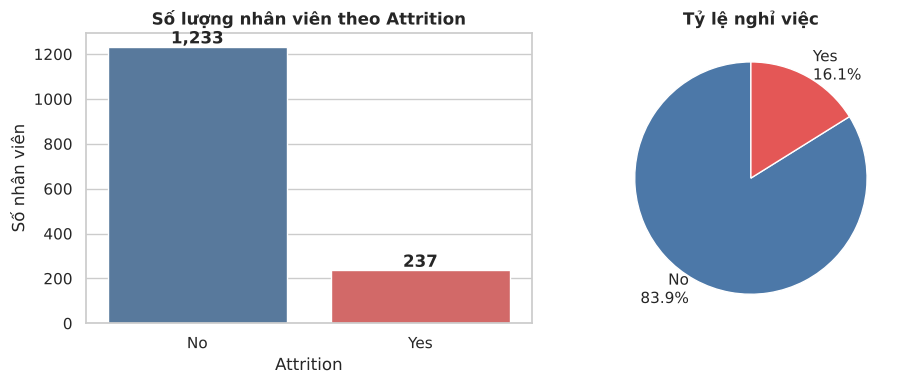

In [9]:
# 1.7 Phân phối biến mục tiêu Attrition (kiểm tra mất cân bằng lớp)
attr_counts = df["Attrition"].value_counts()
attr_pct = df["Attrition"].value_counts(normalize=True) * 100
print(pd.DataFrame({"so_luong": attr_counts, "ty_le_%": attr_pct.round(2)}))
R["attr_yes"], R["attr_no"] = int(attr_counts["Yes"]), int(attr_counts["No"])
R["attr_rate"] = float(attr_pct["Yes"])
R["imbalance_ratio"] = float(attr_counts["No"] / attr_counts["Yes"])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(x=attr_counts.index, y=attr_counts.values, hue=attr_counts.index, palette={"No": C_NO, "Yes": C_YES}, legend=False, ax=ax[0])
for i, v in enumerate(attr_counts.values):
    ax[0].text(i, v + 15, f"{v:,}", ha="center", fontweight="bold")
ax[0].set_title("Số lượng nhân viên theo Attrition"); ax[0].set_xlabel("Attrition"); ax[0].set_ylabel("Số nhân viên")
ax[1].pie(attr_counts.values, labels=[f"{k}\n{v:.1f}%" for k, v in attr_pct.items()], colors=[C_NO, C_YES],
          startangle=90, wedgeprops=dict(edgecolor="white"))
ax[1].set_title("Tỷ lệ nghỉ việc")
plt.tight_layout(); save_fig("fig01_attrition_distribution.png"); plt.show()

### Nhận xét Giai đoạn 1

- Dữ liệu gồm **1.470 nhân viên × 35 thuộc tính**, không có giá trị khuyết (cả khuyết ẩn lẫn NaN) và không có giá trị âm bất hợp lý.
- Chỉ có 1 file nên tiêu chí *tính nhất quán giữa các file* không áp dụng; khóa `EmployeeNumber` duy nhất và đầy đủ.
- Biến mục tiêu **mất cân bằng**: khoảng 16% nghỉ việc, tỷ lệ ở lại : nghỉ khoảng 5,2 : 1. Hệ quả: không nên dùng *accuracy* làm thước đo duy nhất (mô hình đoán "tất cả ở lại" đã đạt ~84%).
- Có 4 cột cần xem xét loại bỏ ở Giai đoạn 2 (`EmployeeCount`, `StandardHours`, `Over18`, `EmployeeNumber`).

---
# GIAI ĐOẠN 2 – TIỀN XỬ LÝ VÀ LÀM SẠCH DỮ LIỆU

Nguyên tắc: mỗi vấn đề phát hiện được đều có **minh chứng** (bảng/biểu đồ/phép tính) và mỗi quyết định xử lý đều có **lý do**.

## 2.1 Dữ liệu trùng lặp

In [10]:
# 2.1 Kiểm tra dòng trùng lặp
dup_full = int(df.duplicated().sum())
dup_wo_id = int(df.drop(columns="EmployeeNumber").duplicated().sum())   # trùng toàn bộ thông tin ngoại trừ mã nhân viên
print("Số dòng trùng hoàn toàn           :", dup_full)
print("Số dòng trùng nếu bỏ qua EmployeeNumber:", dup_wo_id)
R["dup_full"], R["dup_wo_id"] = dup_full, dup_wo_id

Số dòng trùng hoàn toàn           : 0
Số dòng trùng nếu bỏ qua EmployeeNumber: 0


**Kết luận:** không có dòng trùng lặp, kể cả khi bỏ qua cột mã nhân viên → không cần xóa dòng nào.

## 2.2 Cột hằng số và cột định danh
Cột chỉ có một giá trị duy nhất không mang thông tin phân biệt; cột định danh (ID) không có ý nghĩa dự báo và có thể gây nhiễu nếu đưa vào mô hình.

In [11]:
# 2.2 Phát hiện cột hằng số và cột ID bằng nunique()
nun = df.nunique()
const_cols = nun[nun == 1].index.tolist()
id_cols = [c for c in df.columns if df[c].nunique() == len(df) and c != "Attrition"]
print("Cột hằng số:", const_cols)
for c in const_cols:
    print(f"   - {c}: duy nhất giá trị {df[c].unique().tolist()}")
print("Cột định danh (mỗi dòng một giá trị):", id_cols)

DROP_COLS = const_cols + id_cols
df_clean = df.drop(columns=DROP_COLS).copy()      # bản dữ liệu sạch dùng cho phân tích
print(f"\nĐã loại {len(DROP_COLS)} cột {DROP_COLS}; còn lại {df_clean.shape[1]} cột.")
R["drop_cols"], R["n_cols_clean"] = DROP_COLS, int(df_clean.shape[1])

Cột hằng số: ['EmployeeCount', 'Over18', 'StandardHours']
   - EmployeeCount: duy nhất giá trị [1]
   - Over18: duy nhất giá trị ['Y']
   - StandardHours: duy nhất giá trị [80]
Cột định danh (mỗi dòng một giá trị): ['EmployeeNumber']

Đã loại 4 cột ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']; còn lại 31 cột.


## 2.3 Kiểm tra định dạng, miền giá trị và tính hợp lý logic

In [12]:
# 2.3a Kiểm tra định dạng chuỗi (khoảng trắng thừa, viết hoa/thường không nhất quán) và danh sách giá trị hợp lệ
for c in df_clean.select_dtypes(exclude="number").columns:
    s = df_clean[c]
    has_space = int((s != s.str.strip()).sum())
    case_dups = s.str.lower().nunique() != s.nunique()
    print(f"{c:15s} | {s.nunique()} giá trị | khoảng trắng thừa: {has_space} | trùng do hoa/thường: {case_dups} | {sorted(s.unique())}")

Attrition       | 2 giá trị | khoảng trắng thừa: 0 | trùng do hoa/thường: False | ['No', 'Yes']
BusinessTravel  | 3 giá trị | khoảng trắng thừa: 0 | trùng do hoa/thường: False | ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']
Department      | 3 giá trị | khoảng trắng thừa: 0 | trùng do hoa/thường: False | ['Human Resources', 'Research & Development', 'Sales']
EducationField  | 6 giá trị | khoảng trắng thừa: 0 | trùng do hoa/thường: False | ['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']
Gender          | 2 giá trị | khoảng trắng thừa: 0 | trùng do hoa/thường: False | ['Female', 'Male']
JobRole         | 9 giá trị | khoảng trắng thừa: 0 | trùng do hoa/thường: False | ['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']
MaritalStatus   | 3 giá trị | khoảng trắng thừa: 0 | trùng do hoa/thường: False 

In [13]:
# 2.3b Kiểm tra miền giá trị: các biến thứ bậc phải nằm trong thang cho phép; biến số phải nằm trong khoảng hợp lý
ORDINAL_COLS = ["Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel", "JobSatisfaction",
                "PerformanceRating", "RelationshipSatisfaction", "StockOptionLevel", "WorkLifeBalance"]
expected_scale = {c: (1, 4) for c in ["EnvironmentSatisfaction", "JobInvolvement", "JobSatisfaction",
                                      "RelationshipSatisfaction", "WorkLifeBalance", "PerformanceRating"]}
expected_scale.update({"Education": (1, 5), "JobLevel": (1, 5), "StockOptionLevel": (0, 3)})

rows = []
for c in ORDINAL_COLS:
    lo, hi = expected_scale[c]
    vals = sorted(df_clean[c].unique())
    rows.append({"bien": c, "thang_ky_vong": f"{lo}-{hi}", "gia_tri_thuc_te": vals,
                 "ngoai_thang": int((~df_clean[c].between(lo, hi)).sum())})
display(pd.DataFrame(rows))

range_check = {"Age": (18, 65), "MonthlyIncome": (1, None), "DistanceFromHome": (0, None), "PercentSalaryHike": (0, 100),
               "TotalWorkingYears": (0, None), "YearsAtCompany": (0, None)}
for c, (lo, hi) in range_check.items():
    bad = (df_clean[c] < lo).sum() + ((df_clean[c] > hi).sum() if hi is not None else 0)
    print(f"{c:20s} min={df_clean[c].min():>6} max={df_clean[c].max():>6} | ngoài khoảng hợp lý: {int(bad)}")

,bien,thang_ky_vong,gia_tri_thuc_te,ngoai_thang
0,Education,1-5,"[1, 2, 3, 4, 5]",0
1,EnvironmentSatisfaction,1-4,"[1, 2, 3, 4]",0
2,JobInvolvement,1-4,"[1, 2, 3, 4]",0
3,JobLevel,1-5,"[1, 2, 3, 4, 5]",0
4,JobSatisfaction,1-4,"[1, 2, 3, 4]",0
5,PerformanceRating,1-4,"[3, 4]",0
6,RelationshipSatisfaction,1-4,"[1, 2, 3, 4]",0
7,StockOptionLevel,0-3,"[0, 1, 2, 3]",0
8,WorkLifeBalance,1-4,"[1, 2, 3, 4]",0


Age                  min=    18 max=    60 | ngoài khoảng hợp lý: 0
MonthlyIncome        min=  1009 max= 19999 | ngoài khoảng hợp lý: 0
DistanceFromHome     min=     1 max=    29 | ngoài khoảng hợp lý: 0
PercentSalaryHike    min=    11 max=    25 | ngoài khoảng hợp lý: 0
TotalWorkingYears    min=     0 max=    40 | ngoài khoảng hợp lý: 0
YearsAtCompany       min=     0 max=    40 | ngoài khoảng hợp lý: 0


In [14]:
# 2.3c Kiểm tra logic giữa các biến thâm niên (một nhân viên không thể làm ở công ty lâu hơn tổng thời gian đi làm,...)
logic_rules = {
    "YearsAtCompany > TotalWorkingYears":        df_clean["YearsAtCompany"] > df_clean["TotalWorkingYears"],
    "YearsInCurrentRole > YearsAtCompany":       df_clean["YearsInCurrentRole"] > df_clean["YearsAtCompany"],
    "YearsSinceLastPromotion > YearsAtCompany":  df_clean["YearsSinceLastPromotion"] > df_clean["YearsAtCompany"],
    "YearsWithCurrManager > YearsAtCompany":     df_clean["YearsWithCurrManager"] > df_clean["YearsAtCompany"],
    "Tuổi bắt đầu đi làm < 15 (Age - TotalWorkingYears)": (df_clean["Age"] - df_clean["TotalWorkingYears"]) < 15,
}
logic_res = {k: int(v.sum()) for k, v in logic_rules.items()}
display(pd.Series(logic_res, name="so_dong_vi_pham").to_frame())
R["logic_violations"] = logic_res

,so_dong_vi_pham
YearsAtCompany > TotalWorkingYears,0
YearsInCurrentRole > YearsAtCompany,0
YearsSinceLastPromotion > YearsAtCompany,0
YearsWithCurrManager > YearsAtCompany,0
Tuổi bắt đầu đi làm < 15 (Age - TotalWorkingYears),0


In [15]:
# 2.3d Chuẩn hóa kiểu dữ liệu để phân tích: tạo cờ nhị phân cho biến mục tiêu; các biến văn bản chuyển sang 'category'
df_clean["AttritionFlag"] = (df_clean["Attrition"] == "Yes").astype(int)     # 1 = nghỉ việc, 0 = ở lại
for c in df_clean.select_dtypes(exclude="number").columns:
    df_clean[c] = df_clean[c].astype("category")
print(df_clean.dtypes.value_counts())
df_clean.head(3)

int64       24
category     2
category     1
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AttritionFlag
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7,0
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0,1


**Kết luận mục 2.3:** không có lỗi định dạng chuỗi, không có giá trị ngoài thang, và cả 5 ràng buộc logic về tuổi/thâm niên đều có **0 dòng vi phạm**. Lưu ý riêng: `PerformanceRating` chỉ nhận hai giá trị (3 và 4) dù thang là 1–4, nên gần như không phân biệt được nhân viên.
Các biến thang điểm (`Education`, `*Satisfaction`, `JobInvolvement`, `JobLevel`, `StockOptionLevel`, `WorkLifeBalance`, `PerformanceRating`) được lưu dạng số nguyên nhưng bản chất là **thứ bậc (ordinal)** – sẽ được xử lý như biến thứ bậc ở các bước sau.

## 2.4 Giá trị ngoại lệ (outliers)

Hai phương pháp phát hiện được dùng để đối chiếu: **IQR** (ngoài khoảng [Q1 − 1,5·IQR ; Q3 + 1,5·IQR]) và **Z-score** (|z| > 3). IQR không giả định phân phối chuẩn nên phù hợp với dữ liệu lệch; Z-score dùng để đối chiếu.

In [16]:
# 2.4a Phát hiện outlier bằng phương pháp IQR và Z-score cho các biến số liên tục/đếm
CONT_COLS = ["Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome", "MonthlyRate", "NumCompaniesWorked",
             "PercentSalaryHike", "TotalWorkingYears", "TrainingTimesLastYear", "YearsAtCompany", "YearsInCurrentRole",
             "YearsSinceLastPromotion", "YearsWithCurrManager"]

def iqr_mask(s, k=1.5):
    # Trả về mặt nạ outlier theo IQR cùng hai ngưỡng biên
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return (s < lo) | (s > hi), lo, hi

rows = []
for c in CONT_COLS:
    m, lo, hi = iqr_mask(df_clean[c])
    z = np.abs(stats.zscore(df_clean[c]))
    rows.append({"bien": c, "min": df_clean[c].min(), "max": df_clean[c].max(), "skew": round(df_clean[c].skew(), 2),
                 "bien_duoi": round(lo, 1), "bien_tren": round(hi, 1),
                 "n_IQR": int(m.sum()), "%_IQR": round(m.mean() * 100, 1), "n_Z>3": int((z > 3).sum())})
outlier_tbl = pd.DataFrame(rows).sort_values("n_IQR", ascending=False).reset_index(drop=True)
display(outlier_tbl)
outlier_tbl.to_csv(os.path.join(OUT_DIR, "outlier_table.csv"), index=False)
R["outlier_table"] = outlier_tbl.to_dict(orient="records")

,bien,min,max,skew,bien_duoi,bien_tren,n_IQR,%_IQR,n_Z>3
0,TrainingTimesLastYear,0,6,0.55,0.5,4.5,238,16.2,0
1,MonthlyIncome,1009,19999,1.37,-5291.0,16581.0,114,7.8,0
2,YearsSinceLastPromotion,0,15,1.98,-4.5,7.5,107,7.3,42
3,YearsAtCompany,0,40,1.76,-6.0,18.0,104,7.1,25
4,TotalWorkingYears,0,40,1.12,-7.5,28.5,63,4.3,16
5,NumCompaniesWorked,0,9,1.03,-3.5,8.5,52,3.5,0
6,YearsInCurrentRole,0,18,0.92,-5.5,14.5,21,1.4,13
7,YearsWithCurrManager,0,17,0.83,-5.5,14.5,14,1.0,14
8,MonthlyRate,2094,26999,0.02,-10574.8,39083.2,0,0.0,0
9,DailyRate,102,1499,-0.00,-573.0,2195.0,0,0.0,0


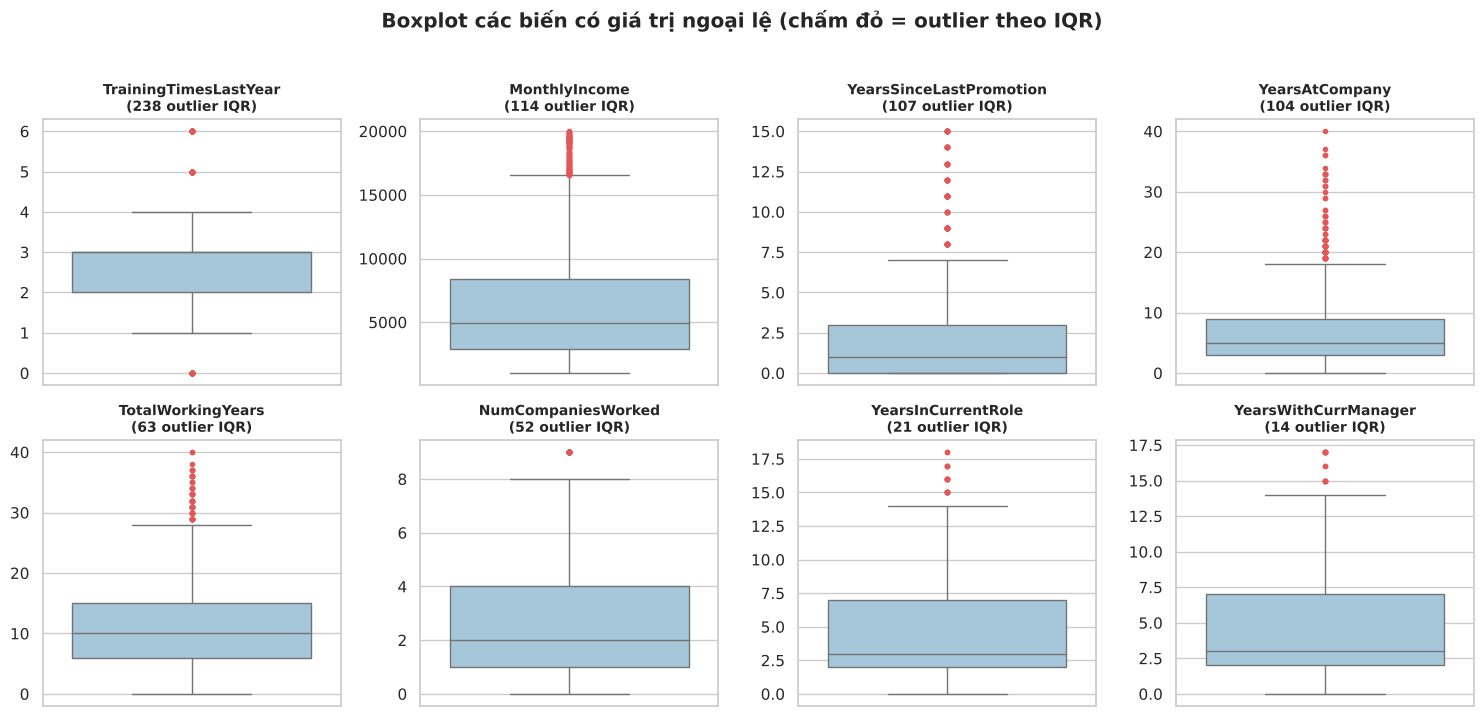

In [17]:
# 2.4b Minh chứng trực quan: boxplot của các biến có outlier theo IQR
box_vars = outlier_tbl.loc[outlier_tbl["n_IQR"] > 0, "bien"].tolist()
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, c in zip(axes.ravel(), box_vars[:8]):
    sns.boxplot(y=df_clean[c], ax=ax, color="#9ecae1", flierprops=dict(marker="o", markersize=3, markerfacecolor=C_YES, markeredgecolor=C_YES))
    n_out = int(outlier_tbl.loc[outlier_tbl["bien"] == c, "n_IQR"].iloc[0])
    ax.set_title(f"{c}\n({n_out} outlier IQR)", fontsize=10); ax.set_ylabel("")
for ax in axes.ravel()[len(box_vars[:8]):]:
    ax.axis("off")
plt.suptitle("Boxplot các biến có giá trị ngoại lệ (chấm đỏ = outlier theo IQR)", fontweight="bold", y=1.02)
plt.tight_layout(); save_fig("fig02_boxplot_outliers.png"); plt.show()

In [18]:
# 2.4c Outlier là lỗi dữ liệu hay giá trị thật? Kiểm chứng bằng ngữ cảnh nghiệp vụ.
# (1) MonthlyIncome: các outlier thuộc cấp bậc/chức danh nào?
m_inc, lo_inc, hi_inc = iqr_mask(df_clean["MonthlyIncome"])
print(f"Ngưỡng trên của MonthlyIncome theo IQR: {hi_inc:,.0f}  | số outlier: {int(m_inc.sum())}")
print("\nCơ cấu JobLevel trong nhóm outlier lương (%):")
print((df_clean.loc[m_inc, "JobLevel"].value_counts(normalize=True).sort_index() * 100).round(1).to_string())
print("\nCơ cấu JobRole trong nhóm outlier lương (%):")
print((df_clean.loc[m_inc, "JobRole"].value_counts(normalize=True) * 100).round(1).head(5).to_string())

# (2) Nếu xóa outlier thì mất đi nhóm nào? So sánh tỷ lệ nghỉ việc
r_out, r_in = df_clean.loc[m_inc, "AttritionFlag"].mean() * 100, df_clean.loc[~m_inc, "AttritionFlag"].mean() * 100
print(f"\nTỷ lệ nghỉ việc: nhóm outlier lương = {r_out:.1f}% | nhóm còn lại = {r_in:.1f}%")

# (3) Các biến thâm niên: outlier có phù hợp với tổng thời gian đi làm không?
m_yac, _, hi_yac = iqr_mask(df_clean["YearsAtCompany"])
print(f"\nYearsAtCompany: ngưỡng trên = {hi_yac:.1f} năm; outlier có TotalWorkingYears trung vị = "
      f"{df_clean.loc[m_yac, 'TotalWorkingYears'].median():.0f} năm (so với toàn bộ: {df_clean['TotalWorkingYears'].median():.0f})")

R["income_outlier"] = {"n": int(m_inc.sum()), "upper_fence": float(hi_inc),
                       "pct_joblevel45": float(df_clean.loc[m_inc, "JobLevel"].isin([4, 5]).mean() * 100),
                       "attr_rate_outlier": float(r_out), "attr_rate_rest": float(r_in)}

Ngưỡng trên của MonthlyIncome theo IQR: 16,581  | số outlier: 114

Cơ cấu JobLevel trong nhóm outlier lương (%):
JobLevel
4    39.5
5    60.5

Cơ cấu JobRole trong nhóm outlier lương (%):
JobRole
Manager                      64.9
Research Director            35.1
Healthcare Representative     0.0
Human Resources               0.0
Laboratory Technician         0.0

Tỷ lệ nghỉ việc: nhóm outlier lương = 4.4% | nhóm còn lại = 17.1%

YearsAtCompany: ngưỡng trên = 18.0 năm; outlier có TotalWorkingYears trung vị = 24 năm (so với toàn bộ: 10)


,skew_truoc,skew_sau_log1p
MonthlyIncome,1.37,0.29
NumCompaniesWorked,1.03,0.09
TotalWorkingYears,1.12,-0.62
YearsAtCompany,1.76,-0.21
YearsSinceLastPromotion,1.98,0.72


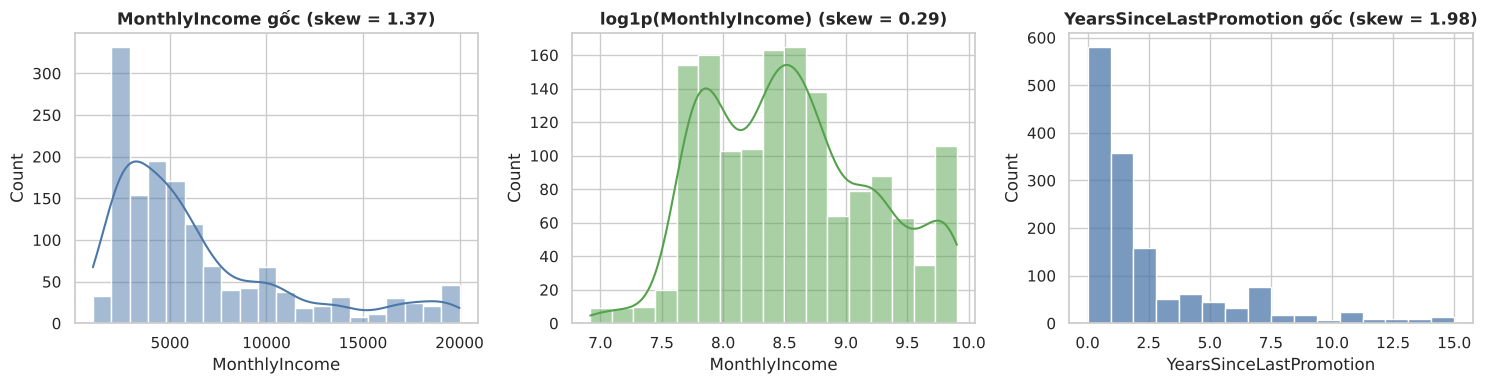

In [19]:
# 2.4d Xử lý độ lệch: biến đổi log1p cho các biến lệch phải mạnh (|skew| > 1), có kiểm chứng bằng skewness trước/sau
SKEW_COLS = [c for c in CONT_COLS if abs(df_clean[c].skew()) > 1]
skew_cmp = pd.DataFrame({"skew_truoc": df_clean[SKEW_COLS].skew(),
                         "skew_sau_log1p": np.log1p(df_clean[SKEW_COLS]).skew()}).round(2)
display(skew_cmp)
R["skew_cols"], R["skew_cmp"] = SKEW_COLS, skew_cmp.reset_index().rename(columns={"index": "bien"}).to_dict(orient="records")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df_clean["MonthlyIncome"], kde=True, color=C_NO, ax=ax[0])
ax[0].set_title(f"MonthlyIncome gốc (skew = {df_clean['MonthlyIncome'].skew():.2f})")
sns.histplot(np.log1p(df_clean["MonthlyIncome"]), kde=True, color="#54A24B", ax=ax[1])
ax[1].set_title(f"log1p(MonthlyIncome) (skew = {np.log1p(df_clean['MonthlyIncome']).skew():.2f})")
sns.histplot(df_clean["YearsSinceLastPromotion"], bins=16, color=C_NO, ax=ax[2])
ax[2].set_title(f"YearsSinceLastPromotion gốc (skew = {df_clean['YearsSinceLastPromotion'].skew():.2f})")
plt.tight_layout(); save_fig("fig03_skew_transform.png"); plt.show()

### Giải trình quyết định xử lý outlier

| Biến | Phát hiện | Quyết định | Lý do |
|---|---|---|---|
| `MonthlyIncome` | Outlier ở đuôi lương cao | **Giữ lại**, dùng `log1p` khi cần cho mô hình | Outlier tập trung ở cấp bậc cao (JobLevel 4–5) nên là lương thật của quản lý; xóa sẽ làm mất nhóm có tỷ lệ nghỉ việc rất thấp và làm lệch kết luận |
| `YearsAtCompany`, `TotalWorkingYears`, `YearsInCurrentRole`, `YearsWithCurrManager` | Đuôi dài ở nhân viên thâm niên | **Giữ lại**, `log1p` với biến lệch mạnh | Thâm niên cao hợp lệ về logic (đã kiểm tra ở 2.3c), là nhóm nhân viên lâu năm có thật |
| `YearsSinceLastPromotion`, `NumCompaniesWorked` | Biến đếm lệch phải | **Giữ lại**, `log1p` | Giá trị lớn là hợp lệ (lâu không thăng chức, nhảy việc nhiều) và có thể chính là tín hiệu nghỉ việc |
| `TrainingTimesLastYear` | IQR gắn cờ nhiều dòng nhưng giá trị chỉ 0–6 lần | **Giữ nguyên** | Biến đếm nhỏ, phân phối rời rạc; "outlier" là hệ quả của IQR hẹp chứ không phải giá trị bất thường |

**Vì sao không xóa hay cắt (winsorize)?** Dữ liệu chỉ có 1.470 dòng và các outlier đều có lý giải nghiệp vụ. Xóa sẽ làm giảm cỡ mẫu và gây thiên lệch; IQR/Z-score chỉ là công cụ *phát hiện*, còn quyết định phải dựa trên ý nghĩa thực tế.
**Vì sao `log1p`?** Dùng `log1p` (thay vì `log`) vì các biến có giá trị 0; phép biến đổi này nén đuôi phải, đưa phân phối về gần đối xứng hơn (xem bảng skew trước/sau) mà không làm mất quan sát nào.

## 2.5 Mã hóa (encoding) và chuẩn hóa (scaling)

In [20]:
# 2.5a Mã hóa biến phân loại
# - Nhị phân (Attrition, OverTime, Gender): ánh xạ 0/1
# - Có thứ tự thật (BusinessTravel): ordinal encoding 0 < 1 < 2 theo mức độ đi công tác
# - Thang điểm đã là số nguyên có thứ tự (Education, *Satisfaction, JobLevel, StockOptionLevel,...): giữ nguyên
# - Danh nghĩa không thứ tự (Department, EducationField, JobRole, MaritalStatus): one-hot (drop_first để tránh đa cộng tuyến hoàn hảo)
NOMINAL_COLS = ["Department", "EducationField", "JobRole", "MaritalStatus"]
TRAVEL_MAP = {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2}

df_model = df_clean.drop(columns=["Attrition"]).copy()
for c in df_model.select_dtypes(exclude="number").columns:
    df_model[c] = df_model[c].astype(str)                                    # bỏ category để map/get_dummies gọn hơn
df_model["OverTime"] = df_model["OverTime"].map({"No": 0, "Yes": 1})
df_model["Gender"] = df_model["Gender"].map({"Female": 0, "Male": 1})
df_model["BusinessTravel"] = df_model["BusinessTravel"].map(TRAVEL_MAP)

# log1p cho các biến lệch phải mạnh (đã xác định ở 2.4d) và đổi tên cột để dễ nhận biết
for c in SKEW_COLS:
    df_model[c + "_log"] = np.log1p(df_model[c])
df_model = df_model.drop(columns=SKEW_COLS)

df_model = pd.get_dummies(df_model, columns=NOMINAL_COLS, drop_first=True, dtype=int)
assert df_model.isna().sum().sum() == 0 and all(pd.api.types.is_numeric_dtype(t) for t in df_model.dtypes)
print("Kích thước ma trận sau mã hóa:", df_model.shape, "(gồm 1 cột mục tiêu AttritionFlag)")
R["model_shape"] = list(df_model.shape)
display(df_model.head(3))

Kích thước ma trận sau mã hóa: (1470, 44) (gồm 1 cột mục tiêu AttritionFlag)


,Age,BusinessTravel,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyRate,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TrainingTimesLastYear,WorkLifeBalance,YearsInCurrentRole,YearsWithCurrManager,AttritionFlag,MonthlyIncome_log,NumCompaniesWorked_log,TotalWorkingYears_log,YearsAtCompany_log,YearsSinceLastPromotion_log,Department_Research & Development,Department_Sales,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,41,1,1102,1,2,2,0,94,3,2,4,19479,1,11,3,1,0,0,1,4,5,1,8.698514,2.197225,2.197225,1.945910,0.000000,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
1,49,2,279,8,1,3,1,61,2,2,2,24907,0,23,4,4,1,3,3,7,7,0,8.543056,0.693147,2.397895,2.397895,0.693147,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0
2,37,1,1373,2,2,4,1,92,2,1,3,2396,1,15,3,2,0,3,3,0,0,1,7.645398,1.945910,2.079442,0.000000,0.000000,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1


In [21]:
# 2.5b Lựa chọn phép chuẩn hóa: StandardScaler dùng (mean, std); RobustScaler dùng (median, IQR).
# Bằng chứng: tham số nào ổn định hơn khi có/không có outlier? (càng ít đổi thì thang đo càng ít bị đuôi dữ liệu chi phối)
stab_rows = []
for c in ["MonthlyIncome", "YearsAtCompany", "YearsSinceLastPromotion"]:
    x = df_clean[c].astype(float)
    m_out, _, _ = iqr_mask(x)
    x_trim = x[~m_out]                                   # dữ liệu sau khi loại outlier (chỉ để so sánh)
    def chg(f): return (f(x) - f(x_trim)) / f(x_trim) * 100
    iqr = lambda v: v.quantile(0.75) - v.quantile(0.25)
    stab_rows.append({"bien": c, "mean_doi_%": round(chg(np.mean), 1), "std_doi_%": round(chg(np.std), 1),
                      "median_doi_%": round(chg(np.median), 1), "IQR_doi_%": round(chg(iqr), 1)})
stab = pd.DataFrame(stab_rows)
print("Mức thay đổi (%) của tham số thang đo khi CÓ so với KHÔNG CÓ outlier:")
display(stab)
R["scaler_stability"] = stab.to_dict(orient="records")

# Kết quả chuẩn hóa thực tế trên biến lệch
cmp_rows = []
for c in ["MonthlyIncome", "YearsAtCompany"]:
    x = df_clean[[c]].astype(float)
    for name, sc in [("StandardScaler", StandardScaler()), ("RobustScaler", RobustScaler())]:
        z = sc.fit_transform(x).ravel()
        cmp_rows.append({"bien": c, "scaler": name, "min": z.min().round(2), "max": z.max().round(2),
                         "trung_vi": np.median(z).round(2), "%_trong_[-1;1]": round((np.abs(z) <= 1).mean() * 100, 1)})
display(pd.DataFrame(cmp_rows))

# Các cột sẽ được chuẩn hóa bằng RobustScaler (liên tục / đếm, sau log nếu có); nhị phân, one-hot, thang điểm giữ nguyên
SCALE_COLS = [c + "_log" if c in SKEW_COLS else c for c in CONT_COLS]
print("\nSố cột chuẩn hóa:", len(SCALE_COLS), "| số cột giữ nguyên:", df_model.shape[1] - 1 - len(SCALE_COLS))
R["scale_cols"] = SCALE_COLS

Mức thay đổi (%) của tham số thang đo khi CÓ so với KHÔNG CÓ outlier:


,bien,mean_doi_%,std_doi_%,median_doi_%,IQR_doi_%
0,MonthlyIncome,18.2,41.8,5.9,36.8
1,YearsAtCompany,21.9,52.3,0.0,-11.1
2,YearsSinceLastPromotion,47.3,61.4,0.0,50.0


,bien,scaler,min,max,trung_vi,%_trong_[-1;1]
0,MonthlyIncome,StandardScaler,-1.17,2.87,-0.34,83.6
1,MonthlyIncome,RobustScaler,-0.72,2.76,0.00,82.3
2,YearsAtCompany,StandardScaler,-1.14,5.39,-0.33,85.0
3,YearsAtCompany,RobustScaler,-0.83,5.83,0.00,85.4



Số cột chuẩn hóa: 14 | số cột giữ nguyên: 29


### Giải trình lựa chọn mã hóa và chuẩn hóa

- **Nhị phân → 0/1:** chỉ có hai trạng thái nên không cần mã hóa phức tạp hơn.
- **`BusinessTravel` → ordinal (0/1/2):** có thứ tự tự nhiên *Non-Travel < Travel_Rarely < Travel_Frequently*; one-hot sẽ làm mất thông tin thứ tự và tăng số chiều không cần thiết.
- **Thang điểm (1–4/1–5) giữ nguyên số nguyên:** đã có thứ tự và khoảng cách xấp xỉ đều; one-hot sẽ thêm hàng chục cột mà không thêm thông tin.
- **`Department`, `EducationField`, `JobRole`, `MaritalStatus` → one-hot (drop_first):** không có thứ tự; gán số 0,1,2,... sẽ tạo ra quan hệ thứ bậc giả. `drop_first=True` tránh đa cộng tuyến hoàn hảo khi dùng hồi quy logistic. Lưu ý: `Department` vẫn được mã hóa để lưu đầy đủ dữ liệu, nhưng **bị loại khỏi mô hình** ở mục 3.12 vì `JobRole` lồng trong `Department` (bằng chứng VIF ở mục 3.12a).
- **`RobustScaler` thay vì `StandardScaler`:** các biến thu nhập, thâm niên lệch phải và có outlier (đã giữ lại). `StandardScaler` dựa vào trung bình và độ lệch chuẩn, còn `RobustScaler` dựa vào trung vị và IQR. Bảng ở 2.5b cho thấy khi loại bỏ outlier, trung bình thay đổi 18–47% còn trung vị chỉ thay đổi 0–6%; độ rộng IQR cũng thay đổi ít hơn độ lệch chuẩn ở cả ba biến (dù mức chênh không đồng đều), tức là thang đo của `RobustScaler` ít bị đuôi dữ liệu chi phối hơn. Cần nói thẳng: trên tập này, tỷ lệ giá trị nằm trong [−1; 1] sau chuẩn hóa của hai phương pháp khá gần nhau, nên chênh lệch kết quả mô hình dự kiến là nhỏ; ta chọn `RobustScaler` vì lý do ổn định, không phải vì nó cho kết quả vượt trội.
- **Chuẩn hóa chỉ được `fit` trên tập huấn luyện** (xem mục 3.12) để tránh rò rỉ dữ liệu (data leakage). Với phần phân tích mô tả/kiểm định (EDA) không cần chuẩn hóa, ta dùng dữ liệu `df_clean` ở thang đo gốc để dễ diễn giải.

---
# GIAI ĐOẠN 3 – PHÂN TÍCH VÀ TRỰC QUAN HÓA

## 3.1 Hệ giả thuyết nghiên cứu

Các giả thuyết được nêu **trước** khi xem số liệu chi tiết, dựa trên kiến thức quản trị nhân sự:

| Mã | Giả thuyết (H₁) | Biến liên quan |
|---|---|---|
| H1 | Nhân viên làm thêm giờ có tỷ lệ nghỉ việc cao hơn | `OverTime` |
| H2 | Nhân viên thu nhập thấp có tỷ lệ nghỉ việc cao hơn (cần kiểm tra yếu tố nhiễu là cấp bậc) | `MonthlyIncome`, `JobLevel` |
| H3 | Nhân viên trẻ tuổi và ít thâm niên nghỉ việc nhiều hơn | `Age`, `YearsAtCompany`, `TotalWorkingYears` |
| H4 | Lâu chưa được thăng chức thì dễ nghỉ việc hơn | `YearsSinceLastPromotion` |
| H5 | Mức hài lòng thấp (công việc, môi trường, cân bằng công việc – cuộc sống) làm tăng nghỉ việc | `JobSatisfaction`, `EnvironmentSatisfaction`, `WorkLifeBalance`, `JobInvolvement` |
| H6 | Có quyền chọn cổ phiếu giúp giữ chân nhân viên | `StockOptionLevel` |
| H7 | Đi công tác thường xuyên, sống độc thân và ở xa công ty làm tăng nghỉ việc | `BusinessTravel`, `MaritalStatus`, `DistanceFromHome` |
| H8 | Tỷ lệ nghỉ việc khác nhau giữa các vị trí công việc | `JobRole`, `Department` |
| H0* | (đối chứng) Giới tính không liên quan đến nghỉ việc | `Gender` |

**Phương pháp kiểm định:**
- Biến phân loại / thang điểm → kiểm định **Chi-square** độc lập; độ mạnh bằng **Cramér's V**.
- Biến số → kiểm định **Mann–Whitney U** (phi tham số vì các biến lệch, không chuẩn); độ mạnh bằng **hệ số rank-biserial** |r|.
- Vì kiểm định đồng thời 30 biến nên áp dụng **hiệu chỉnh Bonferroni** (p × 30) để kiểm soát sai lầm loại I. Mức ý nghĩa α = 0,05.
- **Phân tích độ nhạy:** Bonferroni khá bảo thủ, nên tính thêm **FDR (Benjamini–Hochberg)** để xem kết luận nào phụ thuộc vào cách hiệu chỉnh.
- Khi nghi ngờ **yếu tố nhiễu** (ví dụ hôn nhân, cấp bậc), dùng kiểm định **Cochran–Mantel–Haenszel (CMH)**: so sánh trong từng tầng rồi gộp lại thành một odds ratio chung; kèm kiểm định **Breslow–Day** xem odds ratio có đồng nhất giữa các tầng không.
- Ý nghĩa thống kê ≠ ý nghĩa thực tế: luôn đọc kèm **effect size** và **tỷ lệ phần trăm**.

In [22]:
# 3.1 Các hàm tiện ích dùng chung cho phần kiểm định và vẽ biểu đồ
overall = df_clean["AttritionFlag"].mean() * 100          # tỷ lệ nghỉ việc chung (%)

def cramers_v(ct):
    # Cramér's V từ bảng chéo (không hiệu chỉnh Yates)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

def test_cat(d, col):
    # Chi-square cho biến phân loại/thang điểm so với Attrition
    ct = pd.crosstab(d[col], d["Attrition"])
    chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
    return {"variable": col, "test": "Chi-square", "statistic": chi2, "dof": dof, "p_value": p,
            "effect": cramers_v(ct), "effect_name": "Cramér's V",
            "min_expected": exp.min(), "note": f"min tần số kỳ vọng = {exp.min():.1f}", "direction": ""}

def test_num(d, col):
    # Mann-Whitney U cho biến số; effect size = rank-biserial (dương nếu nhóm nghỉ việc có giá trị lớn hơn)
    a = d.loc[d["Attrition"] == "Yes", col]; b = d.loc[d["Attrition"] == "No", col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * u / (len(a) * len(b)) - 1
    return {"variable": col, "test": "Mann-Whitney U", "statistic": u, "dof": np.nan, "p_value": p,
            "effect": abs(r), "effect_name": "|rank-biserial r|",
            "min_expected": np.nan, "note": f"trung vị Yes = {a.median():g} | No = {b.median():g}",
            "direction": "Nghỉ việc cao hơn" if r > 0 else "Nghỉ việc thấp hơn"}

def odds_ratio(a_yes, a_no, b_yes, b_no):
    # Odds ratio nhóm A so với nhóm B và khoảng tin cậy 95% (Wald)
    o = (a_yes * b_no) / (a_no * b_yes)
    se = np.sqrt(1 / a_yes + 1 / a_no + 1 / b_yes + 1 / b_no)
    return o, np.exp(np.log(o) - 1.96 * se), np.exp(np.log(o) + 1.96 * se)

def cmh_test(d, exposed, strata):
    # Kiểm định Cochran–Mantel–Haenszel: liên hệ giữa 'exposed' (mặt nạ True/False) và Attrition sau khi phân tầng theo 'strata'
    # Trả về OR gộp (Mantel–Haenszel) + KTC 95%, p của CMH (H0: OR gộp = 1) và p Breslow–Day (H0: OR như nhau ở mọi tầng)
    tabs = []
    for _, g in d.groupby(strata, observed=True):
        ct = pd.crosstab(exposed.loc[g.index], g["Attrition"]).reindex(index=[True, False], columns=["Yes", "No"], fill_value=0)
        tabs.append(ct.values)
    st = StratifiedTable(tabs)
    lo, hi = st.oddsratio_pooled_confint()
    return {"OR_pooled": float(st.oddsratio_pooled), "OR_lo": float(lo), "OR_hi": float(hi),
            "p_cmh": float(st.test_null_odds(correction=False).pvalue), "p_breslow_day": float(st.test_equal_odds().pvalue),
            "n_strata": len(tabs)}

def attr_rate(d, col):
    # Tỷ lệ nghỉ việc (%) theo từng nhóm của một biến
    g = d.groupby(col, observed=True)["AttritionFlag"].agg(rate="mean", n="size", left="sum")
    g["rate"] = g["rate"] * 100
    return g

def store_rates(name, g):
    # Lưu bảng tỷ lệ vào R để báo cáo dùng lại
    R.setdefault("rates", {})[name] = {str(k): {"rate": float(v["rate"]), "n": int(v["n"]), "left": int(v["left"])} for k, v in g.iterrows()}

def bar_rate(ax, g, title, xlabel, color=C_YES, rot=0):
    # Biểu đồ cột tỷ lệ nghỉ việc, có nhãn % + cỡ mẫu và đường trung bình chung
    x = g.index.astype(str)
    bars = ax.bar(x, g["rate"], color=color, edgecolor="white", alpha=0.9)
    ax.axhline(overall, ls="--", color="gray", lw=1, label=f"Trung bình chung {overall:.1f}%")
    ax.legend(loc="upper right", fontsize=8, frameon=True)
    for b, r, n in zip(bars, g["rate"], g["n"]):
        ax.text(b.get_x() + b.get_width() / 2, r + 0.4, f"{r:.1f}%\nn={n}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, g["rate"].max() * 1.4)
    ax.set_title(title, fontsize=11); ax.set_xlabel(xlabel); ax.set_ylabel("Tỷ lệ nghỉ việc (%)")
    ax.tick_params(axis="x", rotation=rot)
print("Tỷ lệ nghỉ việc chung: %.2f%%" % overall)

Tỷ lệ nghỉ việc chung: 16.12%


## 3.2 Sàng lọc toàn bộ biến (30 kiểm định, hiệu chỉnh Bonferroni)

Trước khi đi sâu vào từng giả thuyết, kiểm định tất cả 30 biến đầu vào với `Attrition` để có bức tranh tổng thể và xếp hạng theo độ mạnh liên hệ.

In [23]:
# 3.2 Kiểm định đồng loạt 30 biến đầu vào với Attrition
CAT_TEST = ["BusinessTravel", "Department", "EducationField", "Gender", "JobRole", "MaritalStatus", "OverTime"] + ORDINAL_COLS
NUM_TEST = CONT_COLS
screen = pd.DataFrame([test_cat(df_clean, c) for c in CAT_TEST] + [test_num(df_clean, c) for c in NUM_TEST])
m_tests = len(screen)
screen["p_bonferroni"] = np.minimum(screen["p_value"] * m_tests, 1.0)           # hiệu chỉnh Bonferroni
screen["significant"] = screen["p_bonferroni"] < 0.05
screen["p_fdr"] = multipletests(screen["p_value"], method="fdr_bh")[1]        # độ nhạy: FDR Benjamini–Hochberg
screen["significant_fdr"] = screen["p_fdr"] < 0.05
screen = screen.sort_values("effect", ascending=False).reset_index(drop=True)

print(f"Số kiểm định: {m_tests} | có ý nghĩa sau Bonferroni: {int(screen['significant'].sum())} | "
      f"kiểm định Chi-square có tần số kỳ vọng < 5: {int((screen['min_expected'] < 5).sum())} ({', '.join(screen.loc[screen['min_expected'] < 5, 'variable'])})")
only_fdr = screen.loc[screen["significant_fdr"] & ~screen["significant"], "variable"].tolist()
print(f"Có ý nghĩa theo FDR: {int(screen['significant_fdr'].sum())} | chỉ có ý nghĩa với FDR (không qua Bonferroni): {only_fdr}")
show = screen[["variable", "test", "statistic", "p_value", "p_bonferroni", "p_fdr", "effect_name", "effect", "significant", "significant_fdr", "direction", "note"]].copy()
show["p_value"] = show["p_value"].map(lambda v: f"{v:.2e}")
show["p_bonferroni"] = show["p_bonferroni"].map(lambda v: f"{v:.2e}")
show["p_fdr"] = show["p_fdr"].map(lambda v: f"{v:.2e}")
show["effect"] = show["effect"].round(3); show["statistic"] = show["statistic"].round(1)
display(show)
screen.to_csv(os.path.join(OUT_DIR, "screening_tests.csv"), index=False)
R["screen"] = screen.to_dict(orient="records")
R["n_significant"] = int(screen["significant"].sum())
R["n_significant_fdr"], R["only_fdr"] = int(screen["significant_fdr"].sum()), only_fdr

Số kiểm định: 30 | có ý nghĩa sau Bonferroni: 16 | kiểm định Chi-square có tần số kỳ vọng < 5: 1 (EducationField)
Có ý nghĩa theo FDR: 20 | chỉ có ý nghĩa với FDR (không qua Bonferroni): ['DistanceFromHome', 'EducationField', 'DailyRate', 'Department']


,variable,test,statistic,p_value,p_bonferroni,p_fdr,effect_name,effect,significant,significant_fdr,direction,note
0,TotalWorkingYears,Mann-Whitney U,100567.0,2.40e-14,7.20e-13,1.77e-13,|rank-biserial r|,0.312,True,True,Nghỉ việc thấp hơn,trung vị Yes = 7 | No = 10
1,MonthlyIncome,Mann-Whitney U,100620.5,2.95e-14,8.85e-13,1.77e-13,|rank-biserial r|,0.311,True,True,Nghỉ việc thấp hơn,trung vị Yes = 3202 | No = 5204
2,YearsAtCompany,Mann-Whitney U,102582.0,2.92e-13,8.75e-12,1.46e-12,|rank-biserial r|,0.298,True,True,Nghỉ việc thấp hơn,trung vị Yes = 3 | No = 6
3,YearsInCurrentRole,Mann-Whitney U,105214.0,4.43e-12,1.33e-10,1.66e-11,|rank-biserial r|,0.280,True,True,Nghỉ việc thấp hơn,trung vị Yes = 2 | No = 3
4,YearsWithCurrManager,Mann-Whitney U,106361.5,1.81e-11,5.42e-10,6.02e-11,|rank-biserial r|,0.272,True,True,Nghỉ việc thấp hơn,trung vị Yes = 2 | No = 3
5,Age,Mann-Whitney U,106859.0,5.30e-11,1.59e-09,1.59e-10,|rank-biserial r|,0.269,True,True,Nghỉ việc thấp hơn,trung vị Yes = 32 | No = 36
6,OverTime,Chi-square,89.0,3.86e-21,1.16e-19,1.16e-19,Cramér's V,0.246,True,True,,min tần số kỳ vọng = 67.1
7,JobRole,Chi-square,86.2,2.75e-15,8.26e-14,4.13e-14,Cramér's V,0.242,True,True,,min tần số kỳ vọng = 8.4
8,JobLevel,Chi-square,72.5,6.63e-15,1.99e-13,6.63e-14,Cramér's V,0.222,True,True,,min tần số kỳ vọng = 11.1
9,StockOptionLevel,Chi-square,60.6,4.38e-13,1.31e-11,1.88e-12,Cramér's V,0.203,True,True,,min tần số kỳ vọng = 13.7


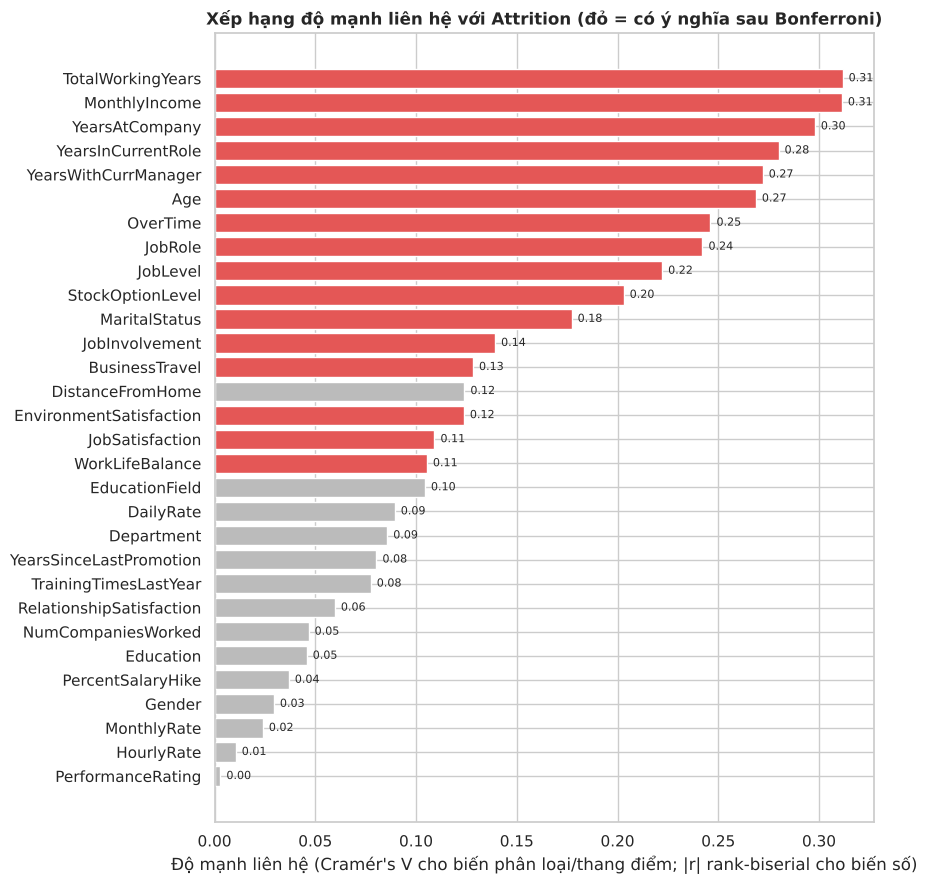

In [24]:
# 3.2b Biểu đồ xếp hạng độ mạnh liên hệ giữa các biến và Attrition (màu đỏ = có ý nghĩa sau Bonferroni)
s = screen.sort_values("effect")
fig, ax = plt.subplots(figsize=(9, 9))
colors = [C_YES if sig else "#bbbbbb" for sig in s["significant"]]
ax.barh(s["variable"], s["effect"], color=colors)
for i, (e, nm) in enumerate(zip(s["effect"], s["effect_name"])):
    ax.text(e + 0.003, i, f"{e:.2f}", va="center", fontsize=8)
ax.set_xlabel("Độ mạnh liên hệ (Cramér's V cho biến phân loại/thang điểm; |r| rank-biserial cho biến số)")
ax.set_title("Xếp hạng độ mạnh liên hệ với Attrition (đỏ = có ý nghĩa sau Bonferroni)")
plt.tight_layout(); save_fig("fig04_effect_ranking.png"); plt.show()

## 3.3 H1 – Làm thêm giờ (`OverTime`)

**Khung kiểm định 5 bước**

| Bước | Nội dung |
|---|---|
| 1. Cặp giả thuyết | **H₀:** tỷ lệ nghỉ việc độc lập với việc làm thêm giờ.<br>**H₁:** tỷ lệ nghỉ việc khác nhau giữa nhóm làm thêm giờ và không làm thêm giờ (kỳ vọng: nhóm làm thêm giờ cao hơn). |
| 2. Dữ liệu và giả định | `OverTime` và `Attrition` đều nhị phân → bảng chéo 2×2; mọi tần số kỳ vọng ≥ 5 nên dùng được Chi-square. |
| 3. Kiểm định | Chi-square độc lập (hai phía) + Cramér's V; odds ratio và risk ratio kèm KTC 95%; kiểm định CMH (mục H1b) để loại trừ nhiễu do hôn nhân, cấp bậc. |
| 4. Tính toán | Thống kê kiểm định, p-value, effect size (ô code bên dưới); p hiệu chỉnh Bonferroni lấy từ mục 3.2 |
| 5. Quy tắc kết luận | Bác bỏ H₀ nếu p sau hiệu chỉnh Bonferroni < 0,05; đọc kèm effect size và chênh lệch tỷ lệ để đánh giá ý nghĩa thực tế. |


           rate     n  left
OverTime                   
No        10.44  1054   110
Yes       30.53   416   127

Chi-square = 89.04, p = 3.86e-21, Cramér's V = 0.246
Odds ratio (OverTime=Yes so với No) = 3.77  (KTC 95%: 2.83 – 5.03)
Tỷ số tỷ lệ (risk ratio) = 2.93

Tỷ lệ nghỉ việc (%) theo MaritalStatus × OverTime:
OverTime         No   Yes
MaritalStatus            
Single         16.2  49.6
Married         8.4  23.1
Divorced        6.1  19.2

Cỡ mẫu:
OverTime        No  Yes
MaritalStatus          
Single         339  131
Married        487  186
Divorced       228   99


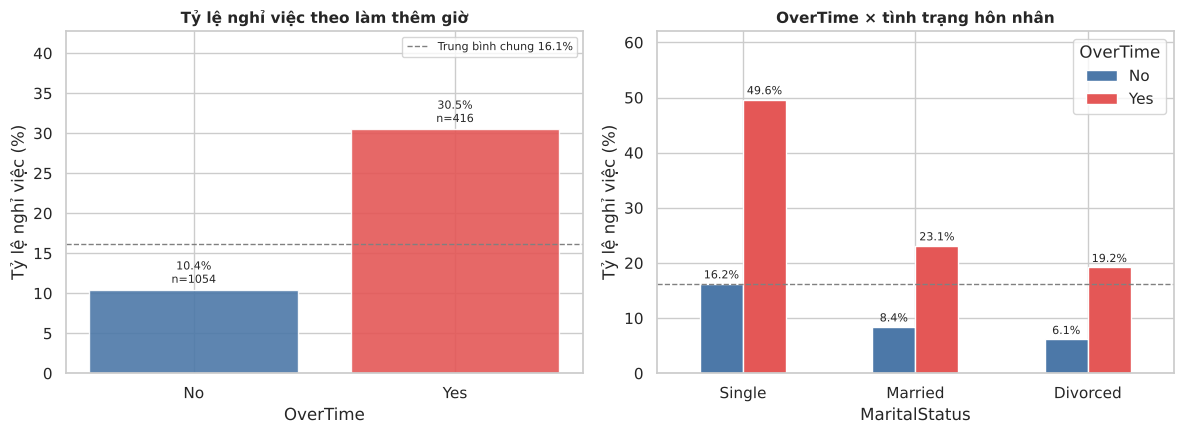

In [25]:
# H1: Tỷ lệ nghỉ việc theo OverTime + odds ratio + chi-square; và hiệu ứng OverTime trong từng nhóm hôn nhân
g = attr_rate(df_clean, "OverTime").loc[["No", "Yes"]]
ct = pd.crosstab(df_clean["OverTime"], df_clean["Attrition"])
or_, or_lo, or_hi = odds_ratio(ct.loc["Yes", "Yes"], ct.loc["Yes", "No"], ct.loc["No", "Yes"], ct.loc["No", "No"])
t = test_cat(df_clean, "OverTime")
print(g.round(2))
print(f"\nChi-square = {t['statistic']:.2f}, p = {t['p_value']:.2e}, Cramér's V = {t['effect']:.3f}")
print(f"Odds ratio (OverTime=Yes so với No) = {or_:.2f}  (KTC 95%: {or_lo:.2f} – {or_hi:.2f})")
print(f"Tỷ số tỷ lệ (risk ratio) = {g.loc['Yes','rate'] / g.loc['No','rate']:.2f}")
store_rates("OverTime", g)
R["H1"] = {"chi2": float(t["statistic"]), "p": float(t["p_value"]), "V": float(t["effect"]), "OR": float(or_), "OR_lo": float(or_lo),
           "OR_hi": float(or_hi), "RR": float(g.loc["Yes", "rate"] / g.loc["No", "rate"])}

piv = df_clean.groupby(["MaritalStatus", "OverTime"], observed=True)["AttritionFlag"].agg(rate="mean", n="size", left="sum")
piv["rate"] *= 100
store_rates("OverTime_x_Marital", piv.rename(index=lambda x: x))
rate_tab = piv["rate"].unstack().loc[["Single", "Married", "Divorced"]]
print("\nTỷ lệ nghỉ việc (%) theo MaritalStatus × OverTime:"); print(rate_tab.round(1))
print("\nCỡ mẫu:"); print(piv["n"].unstack().loc[["Single", "Married", "Divorced"]])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
bar_rate(ax[0], g, "Tỷ lệ nghỉ việc theo làm thêm giờ", "OverTime", color=[C_NO, C_YES])
rate_tab.plot.bar(ax=ax[1], color=[C_NO, C_YES], rot=0, edgecolor="white")
for cont in ax[1].containers:
    ax[1].bar_label(cont, fmt="%.1f%%", fontsize=8, padding=2)
ax[1].axhline(overall, ls="--", color="gray", lw=1)
ax[1].set_title("OverTime × tình trạng hôn nhân", fontsize=11); ax[1].set_ylabel("Tỷ lệ nghỉ việc (%)"); ax[1].set_ylim(0, rate_tab.values.max() * 1.25)
ax[1].legend(title="OverTime")
plt.tight_layout(); save_fig("fig05_overtime.png"); plt.show()

### H1b – OverTime có bị nhiễu bởi tình trạng hôn nhân hay cấp bậc? (kiểm định CMH)

Biểu đồ bên phải cho thấy hiệu ứng làm thêm giờ xuất hiện ở cả ba nhóm hôn nhân. Để kết luận chắc chắn hơn việc chỉ nhìn biểu đồ, dùng kiểm định **Cochran–Mantel–Haenszel**: tính odds ratio trong từng tầng (hôn nhân / cấp bậc) rồi gộp lại. Nếu OR gộp vẫn lớn và có ý nghĩa thì liên hệ OverTime – nghỉ việc **không phải do** yếu tố phân tầng gây ra. Kiểm định **Breslow–Day** cho biết OR có đồng nhất giữa các tầng không (p lớn ⇒ hiệu ứng tương tự ở mọi tầng).

In [26]:
# H1b: Kiểm định CMH cho OverTime, phân tầng lần lượt theo MaritalStatus và JobLevel
ot_yes = df_clean["OverTime"] == "Yes"
cmh_rows = []
for strata in ["MaritalStatus", "JobLevel"]:
    r = cmh_test(df_clean, ot_yes, strata)
    cmh_rows.append({"phan_tang_theo": strata, "so_tang": r["n_strata"], "OR_gop_MH": round(r["OR_pooled"], 2),
                     "KTC_95%": f"{r['OR_lo']:.2f} – {r['OR_hi']:.2f}", "p_CMH": f"{r['p_cmh']:.1e}" if r["p_cmh"] > 0 else "< 1e-16",
                     "p_Breslow_Day": round(r["p_breslow_day"], 3)})
    R.setdefault("CMH", {})[f"OverTime|{strata}"] = r
print(f"OR thô (chưa phân tầng) = {R['H1']['OR']:.2f}")
display(pd.DataFrame(cmh_rows))

OR thô (chưa phân tầng) = 3.77


,phan_tang_theo,so_tang,OR_gop_MH,KTC_95%,p_CMH,p_Breslow_Day
0,MaritalStatus,3,4.04,3.01 – 5.42,< 1e-16,0.390
1,JobLevel,5,4.05,3.01 – 5.46,< 1e-16,0.084


**Nhận xét H1b:** OR thô là 3,77; sau khi phân tầng theo hôn nhân OR gộp là **4,04** (KTC 95%: 3,01–5,42), theo cấp bậc là **4,05** (3,01–5,46), p CMH < 10⁻¹⁶. OR không giảm mà còn tăng nhẹ khi phân tầng, nên liên hệ giữa làm thêm giờ và nghỉ việc **không phải do** hôn nhân hay cấp bậc gây ra. Breslow–Day p = 0,39 (hôn nhân) và 0,08 (cấp bậc): chưa có bằng chứng OR khác nhau giữa các tầng, tức là làm thêm giờ làm tăng odds nghỉ việc khoảng 4 lần **ở mọi nhóm**. Tỷ lệ 49,6% ở nhóm độc thân làm thêm giờ là do hai yếu tố cộng lại, không phải do OverTime tác động mạnh hơn riêng ở nhóm này.

## 3.4 H2 – Thu nhập (`MonthlyIncome`) và yếu tố nhiễu cấp bậc (`JobLevel`)

**Khung kiểm định 5 bước**

| Bước | Nội dung |
|---|---|
| 1. Cặp giả thuyết | **H₀:** phân phối thu nhập của nhóm nghỉ việc và nhóm ở lại như nhau, cả trên toàn bộ dữ liệu lẫn trong từng `JobLevel`.<br>**H₁:** nhóm nghỉ việc có thu nhập khác (kỳ vọng: thấp hơn) nhóm ở lại. |
| 2. Dữ liệu và giả định | `MonthlyIncome` lệch phải (skew 1,37), không chuẩn → dùng kiểm định phi tham số. `JobLevel` là yếu tố nhiễu tiềm năng (tương quan 0,92 với thu nhập) → cần phân tầng. |
| 3. Kiểm định | Mann–Whitney U hai phía + rank-biserial |r| trên toàn bộ dữ liệu; Mann–Whitney U lặp lại trong từng `JobLevel` (kiểm soát cấp bậc). |
| 4. Tính toán | Thống kê kiểm định, p-value, effect size (ô code bên dưới); p hiệu chỉnh Bonferroni lấy từ mục 3.2 |
| 5. Quy tắc kết luận | Bác bỏ H₀ nếu p sau hiệu chỉnh Bonferroni < 0,05; đọc kèm effect size và chênh lệch tỷ lệ để đánh giá ý nghĩa thực tế. Với phân tầng theo JobLevel dùng mức 0,05 chưa hiệu chỉnh và ghi rõ cỡ mẫu từng tầng. |


            count    mean     25%     50%     75%
Attrition                                        
No         1233.0  6833.0  3211.0  5204.0  8834.0
Yes         237.0  4787.0  2373.0  3202.0  5916.0

Mann-Whitney U: p = 2.95e-14, |r| = 0.311, Nghỉ việc thấp hơn

Theo tứ phân vị thu nhập:
                 rate    n  left
IncomeQuartile                  
Q1 (thấp)       29.27  369   108
Q2              14.21  366    52
Q3              10.63  367    39
Q4 (cao)        10.33  368    38

Theo JobLevel:
           rate    n  left
JobLevel                  
1         26.34  543   143
2          9.74  534    52
3         14.68  218    32
4          4.72  106     5
5          7.25   69     5

So sánh thu nhập theo từng JobLevel (kiểm soát cấp bậc):


,JobLevel,n,n_nghi,TV_thu_nhap_nghi,TV_thu_nhap_o_lai,p_MWU
0,1,543,143,2437.0,2719.0,0.0004
1,2,534,52,5346.0,5334.5,0.3072
2,3,218,32,9887.0,9982.5,0.1605
3,4,106,5,13194.0,16307.0,0.0040
4,5,69,5,19545.0,19199.5,0.2057


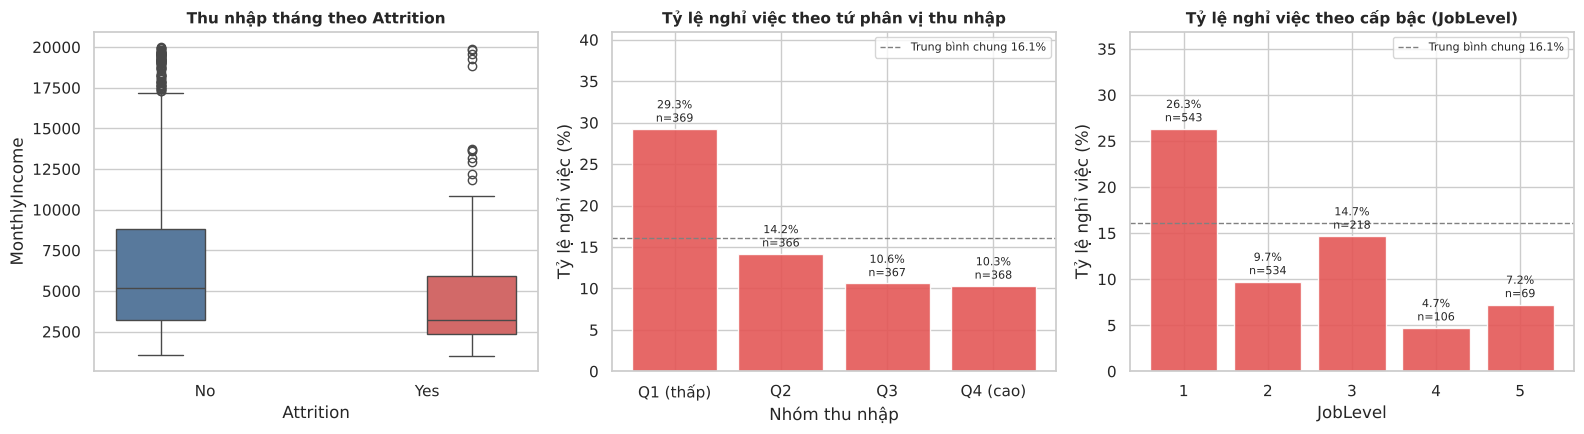

In [27]:
# H2a: So sánh thu nhập giữa hai nhóm, tỷ lệ nghỉ việc theo tứ phân vị thu nhập và theo JobLevel
t = test_num(df_clean, "MonthlyIncome")
inc = df_clean.groupby("Attrition", observed=True)["MonthlyIncome"].describe()[["count", "mean", "25%", "50%", "75%"]]
print(inc.round(0))
print(f"\nMann-Whitney U: p = {t['p_value']:.2e}, |r| = {t['effect']:.3f}, {t['direction']}")

df_clean["IncomeQuartile"] = pd.qcut(df_clean["MonthlyIncome"], 4, labels=["Q1 (thấp)", "Q2", "Q3", "Q4 (cao)"])
g_q = attr_rate(df_clean, "IncomeQuartile")
g_jl = attr_rate(df_clean, "JobLevel")
print("\nTheo tứ phân vị thu nhập:"); print(g_q.round(2))
print("\nTheo JobLevel:"); print(g_jl.round(2))
store_rates("IncomeQuartile", g_q); store_rates("JobLevel", g_jl)

# Kiểm tra nhiễu: trong từng JobLevel, thu nhập của nhóm nghỉ việc có còn thấp hơn không?
rows = []
for lv, d in df_clean.groupby("JobLevel", observed=True):
    a, b = d.loc[d["Attrition"] == "Yes", "MonthlyIncome"], d.loc[d["Attrition"] == "No", "MonthlyIncome"]
    p = stats.mannwhitneyu(a, b).pvalue if len(a) > 1 else np.nan
    rows.append({"JobLevel": lv, "n": len(d), "n_nghi": len(a), "TV_thu_nhap_nghi": a.median(), "TV_thu_nhap_o_lai": b.median(), "p_MWU": p})
strat = pd.DataFrame(rows)
print("\nSo sánh thu nhập theo từng JobLevel (kiểm soát cấp bậc):"); display(strat.round(4))
R["H2"] = {"p": float(t["p_value"]), "r": float(t["effect"]), "median_yes": float(inc.loc["Yes", "50%"]), "median_no": float(inc.loc["No", "50%"]),
           "mean_yes": float(inc.loc["Yes", "mean"]), "mean_no": float(inc.loc["No", "mean"]), "strat": strat.to_dict(orient="records")}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df_clean, x="Attrition", y="MonthlyIncome", hue="Attrition", order=["No", "Yes"], palette={"No": C_NO, "Yes": C_YES}, legend=False, ax=ax[0])
ax[0].set_title("Thu nhập tháng theo Attrition", fontsize=11); ax[0].set_ylabel("MonthlyIncome")
bar_rate(ax[1], g_q, "Tỷ lệ nghỉ việc theo tứ phân vị thu nhập", "Nhóm thu nhập")
bar_rate(ax[2], g_jl, "Tỷ lệ nghỉ việc theo cấp bậc (JobLevel)", "JobLevel")
plt.tight_layout(); save_fig("fig06_income.png"); plt.show()

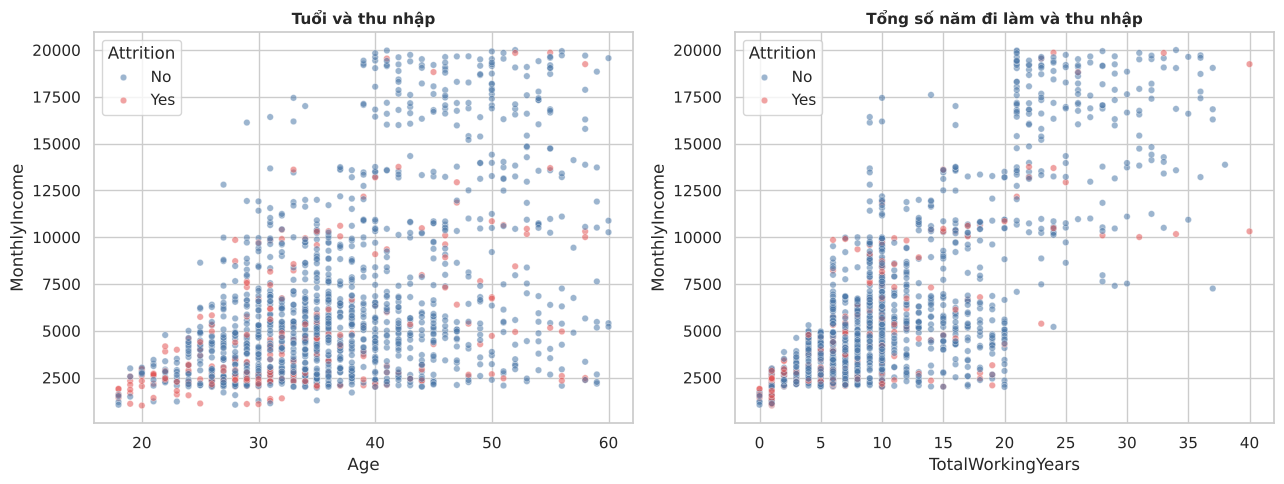

Spearman: Age–MonthlyIncome = 0.47 | TotalWorkingYears–MonthlyIncome = 0.71 | JobLevel–MonthlyIncome = 0.92


In [28]:
# H2b: Scatter plot – thu nhập phụ thuộc mạnh vào tuổi/thâm niên; nhóm nghỉ việc nằm ở đâu?
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, xcol, ttl in [(ax[0], "Age", "Tuổi và thu nhập"), (ax[1], "TotalWorkingYears", "Tổng số năm đi làm và thu nhập")]:
    sns.scatterplot(data=df_clean, x=xcol, y="MonthlyIncome", hue="Attrition", hue_order=["No", "Yes"],
                    palette={"No": C_NO, "Yes": C_YES}, alpha=0.55, s=22, ax=a)
    a.set_title(ttl, fontsize=11)
plt.tight_layout(); save_fig("fig07_scatter_income.png"); plt.show()

rho_age, _ = stats.spearmanr(df_clean["Age"], df_clean["MonthlyIncome"])
rho_twy, _ = stats.spearmanr(df_clean["TotalWorkingYears"], df_clean["MonthlyIncome"])
rho_jl, _ = stats.spearmanr(df_clean["JobLevel"], df_clean["MonthlyIncome"])
print(f"Spearman: Age–MonthlyIncome = {rho_age:.2f} | TotalWorkingYears–MonthlyIncome = {rho_twy:.2f} | JobLevel–MonthlyIncome = {rho_jl:.2f}")
R["H2"].update({"rho_age": float(rho_age), "rho_twy": float(rho_twy), "rho_jl": float(rho_jl)})

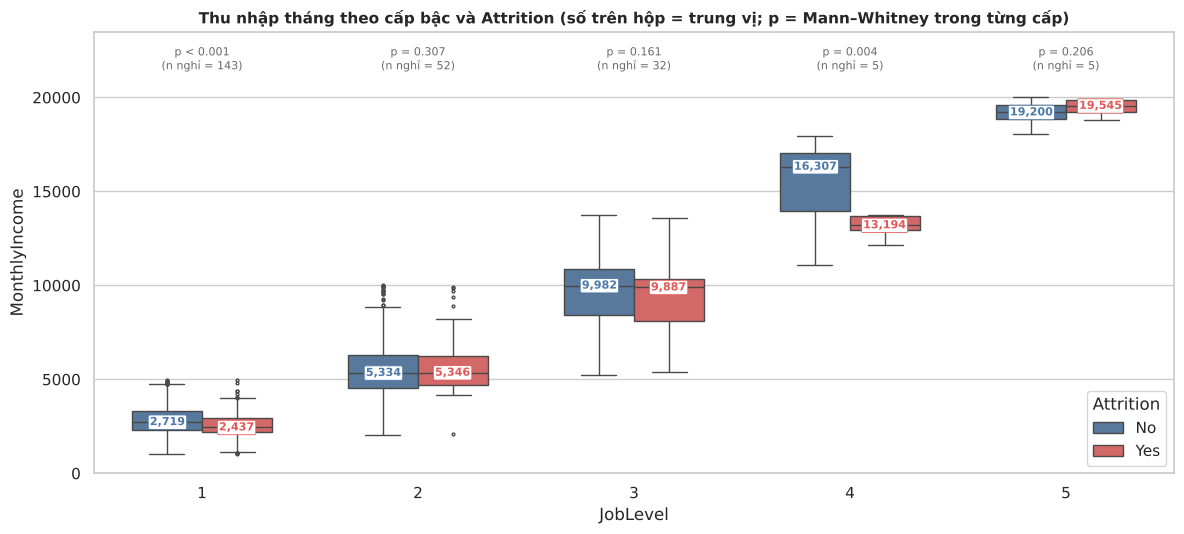

In [29]:
# H2c: Boxplot thu nhập theo từng JobLevel, tách theo Attrition, ghi trung vị – minh họa trực quan cho phần kiểm soát cấp bậc của H2
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.boxplot(data=df_clean, x="JobLevel", y="MonthlyIncome", hue="Attrition", hue_order=["No", "Yes"],
            palette={"No": C_NO, "Yes": C_YES}, width=0.65, fliersize=2, ax=ax)
levels = sorted(df_clean["JobLevel"].unique())
for k, lv in enumerate(levels):
    for off, grp, col in [(-0.16, "No", C_NO), (0.16, "Yes", C_YES)]:
        s_ = df_clean.loc[(df_clean["JobLevel"] == lv) & (df_clean["Attrition"] == grp), "MonthlyIncome"]
        ax.text(k + off, s_.median(), f"{s_.median():,.0f}", ha="center", va="center", fontsize=8, color=col, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=col, lw=0.6))
    p_lv = strat.loc[strat["JobLevel"] == lv, "p_MWU"].iloc[0]
    n_left = int(strat.loc[strat["JobLevel"] == lv, "n_nghi"].iloc[0])
    p_txt = "p < 0.001" if p_lv < 0.001 else f"p = {p_lv:.3f}"
    ax.text(k, 21500, f"{p_txt}\n(n nghỉ = {n_left})", ha="center", fontsize=8, color="dimgray")
ax.set_ylim(0, 23500)
ax.set_title("Thu nhập tháng theo cấp bậc và Attrition (số trên hộp = trung vị; p = Mann–Whitney trong từng cấp)", fontsize=11)
ax.set_xlabel("JobLevel"); ax.set_ylabel("MonthlyIncome"); ax.legend(title="Attrition", loc="lower right")
plt.tight_layout(); save_fig("fig06b_income_by_joblevel.png"); plt.show()

**Nhận xét H2c:** khi đặt cạnh nhau trong từng cấp bậc, hộp của người nghỉ (đỏ) và người ở lại (xanh) gần như trùng nhau ở JobLevel 2, 3 và 5 (trung vị 5.346 so với 5.334; 9.887 so với 9.982; 19.545 so với 19.200). Khác biệt chỉ thấy rõ ở JobLevel 1 (2.437 so với 2.719, thấp hơn khoảng 10%) và JobLevel 4 (13.194 so với 16.307, nhưng chỉ có 5 người nghỉ). Trong khi đó, khoảng cách thu nhập **giữa các cấp** lớn hơn nhiều lần khoảng cách **trong cùng cấp**. Hình này cho thấy trực quan vì sao chênh lệch thu nhập tổng thể (3.202 so với 5.204) chủ yếu là hiệu ứng của cấp bậc: người nghỉ việc tập trung ở JobLevel 1. Hàm ý: ưu tiên rà soát mặt bằng lương JobLevel 1 và lộ trình lên JobLevel 2, không tăng lương đại trà.

## 3.5 H3 – Tuổi và thâm niên

**Khung kiểm định 5 bước**

| Bước | Nội dung |
|---|---|
| 1. Cặp giả thuyết | **H₀:** tuổi, thâm niên tại công ty và tổng số năm đi làm có phân phối như nhau ở hai nhóm.<br>**H₁:** nhóm nghỉ việc khác (kỳ vọng: trẻ hơn, ít thâm niên hơn) nhóm ở lại. |
| 2. Dữ liệu và giả định | Ba biến định lượng; `YearsAtCompany`, `TotalWorkingYears` lệch phải → kiểm định phi tham số. Chia nhóm tuổi/thâm niên để đọc tỷ lệ. |
| 3. Kiểm định | Mann–Whitney U hai phía + rank-biserial |r| cho từng biến; tỷ lệ nghỉ việc theo nhóm tuổi và nhóm thâm niên. |
| 4. Tính toán | Thống kê kiểm định, p-value, effect size (ô code bên dưới); p hiệu chỉnh Bonferroni lấy từ mục 3.2 |
| 5. Quy tắc kết luận | Bác bỏ H₀ nếu p sau hiệu chỉnh Bonferroni < 0,05; đọc kèm effect size và chênh lệch tỷ lệ để đánh giá ý nghĩa thực tế. |


           rate    n  left
AgeGroup                  
18–24     39.18   97    38
25–34     20.22  554   112
35–44     10.10  505    51
45–54     10.20  245    25
55+       15.94   69    11

              rate    n  left
TenureGroup                  
0–1          34.88  215    75
2–3          18.43  255    47
4–5          13.07  306    40
6–10         12.28  448    55
>10           8.13  246    20
Age               : trung vị Yes = 32 | No = 36 | p = 5.30e-11 | |r| = 0.269 | Nghỉ việc thấp hơn
YearsAtCompany    : trung vị Yes = 3 | No = 6 | p = 2.92e-13 | |r| = 0.298 | Nghỉ việc thấp hơn
TotalWorkingYears : trung vị Yes = 7 | No = 10 | p = 2.40e-14 | |r| = 0.312 | Nghỉ việc thấp hơn

Nghỉ việc khi thâm niên ≤ 1 năm: 34.9% | > 1 năm: 12.9%


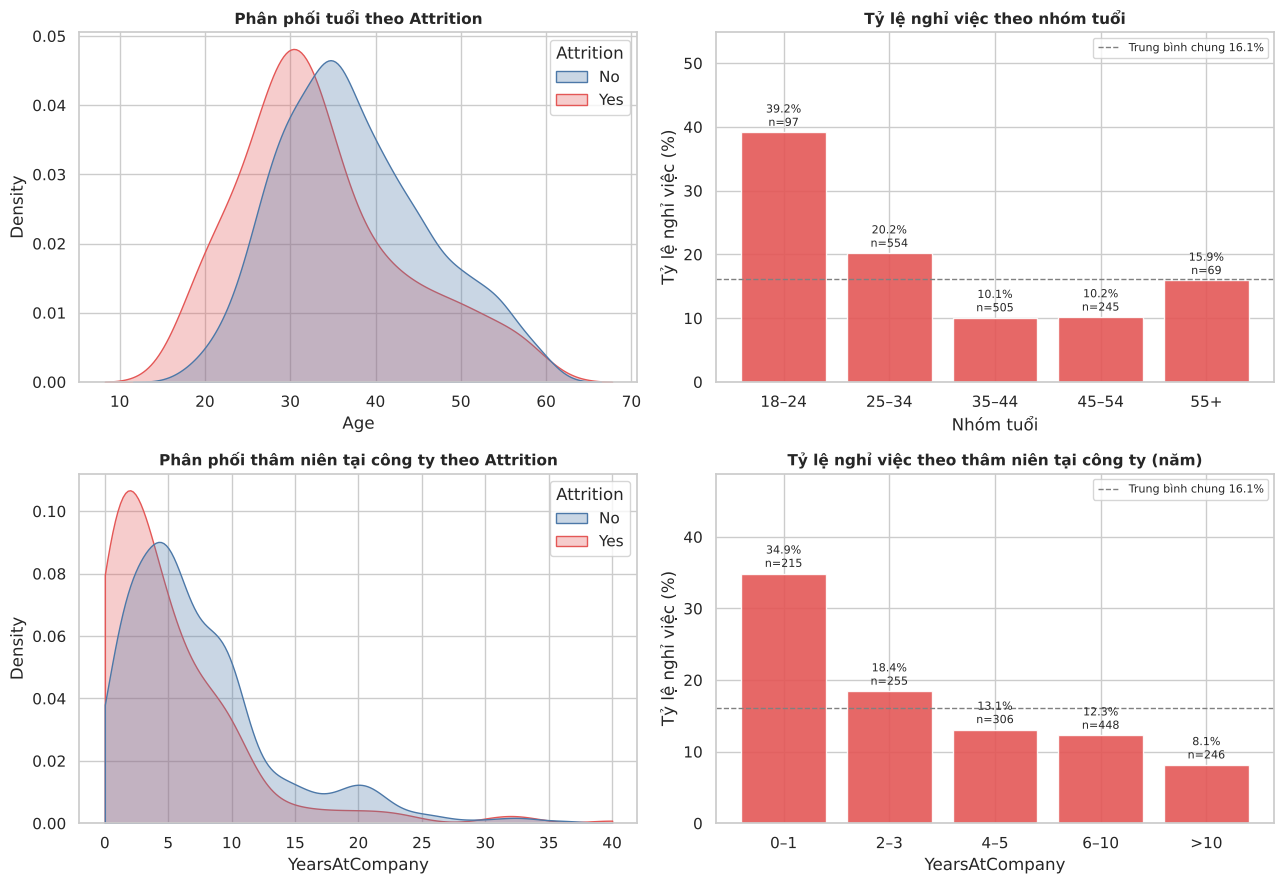

In [30]:
# H3: Tuổi và thâm niên – phân phối (KDE) và tỷ lệ nghỉ việc theo nhóm
df_clean["AgeGroup"] = pd.cut(df_clean["Age"], [17, 24, 34, 44, 54, 70], labels=["18–24", "25–34", "35–44", "45–54", "55+"])
df_clean["TenureGroup"] = pd.cut(df_clean["YearsAtCompany"], [-1, 1, 3, 5, 10, 50], labels=["0–1", "2–3", "4–5", "6–10", ">10"])
g_age, g_ten = attr_rate(df_clean, "AgeGroup"), attr_rate(df_clean, "TenureGroup")
print(g_age.round(2)); print(); print(g_ten.round(2))
store_rates("AgeGroup", g_age); store_rates("TenureGroup", g_ten)

for c in ["Age", "YearsAtCompany", "TotalWorkingYears"]:
    t = test_num(df_clean, c)
    print(f"{c:18s}: {t['note']} | p = {t['p_value']:.2e} | |r| = {t['effect']:.3f} | {t['direction']}")
R["H3"] = {c: {"p": float(test_num(df_clean, c)["p_value"]), "r": float(test_num(df_clean, c)["effect"]),
               "note": test_num(df_clean, c)["note"]} for c in ["Age", "YearsAtCompany", "TotalWorkingYears"]}
first2 = df_clean.loc[df_clean["YearsAtCompany"] <= 1, "AttritionFlag"].mean() * 100
rest = df_clean.loc[df_clean["YearsAtCompany"] > 1, "AttritionFlag"].mean() * 100
print(f"\nNghỉ việc khi thâm niên ≤ 1 năm: {first2:.1f}% | > 1 năm: {rest:.1f}%")
R["H3"].update({"first_year": float(first2), "after_first_year": float(rest)})

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.kdeplot(data=df_clean, x="Age", hue="Attrition", hue_order=["No", "Yes"], palette={"No": C_NO, "Yes": C_YES}, common_norm=False, fill=True, alpha=0.3, ax=ax[0, 0])
ax[0, 0].set_title("Phân phối tuổi theo Attrition", fontsize=11)
bar_rate(ax[0, 1], g_age, "Tỷ lệ nghỉ việc theo nhóm tuổi", "Nhóm tuổi")
sns.kdeplot(data=df_clean, x="YearsAtCompany", hue="Attrition", hue_order=["No", "Yes"], palette={"No": C_NO, "Yes": C_YES}, common_norm=False, fill=True, alpha=0.3, clip=(0, 40), ax=ax[1, 0])
ax[1, 0].set_title("Phân phối thâm niên tại công ty theo Attrition", fontsize=11)
bar_rate(ax[1, 1], g_ten, "Tỷ lệ nghỉ việc theo thâm niên tại công ty (năm)", "YearsAtCompany")
plt.tight_layout(); save_fig("fig08_age_tenure.png"); plt.show()

## 3.6 H4 – Thời gian kể từ lần thăng chức gần nhất

**Khung kiểm định 5 bước**

| Bước | Nội dung |
|---|---|
| 1. Cặp giả thuyết | **H₀:** số năm kể từ lần thăng chức gần nhất có phân phối như nhau ở hai nhóm.<br>**H₁:** nhóm nghỉ việc khác (kỳ vọng: lâu chưa thăng chức hơn) nhóm ở lại. |
| 2. Dữ liệu và giả định | Biến đếm 0–15, rất lệch (skew 1,98) và dồn ở giá trị 0; ràng buộc YearsSinceLastPromotion ≤ YearsAtCompany nên nhân viên mới luôn có giá trị 0. |
| 3. Kiểm định | Mann–Whitney U hai phía + |r|; tỷ lệ nghỉ việc theo nhóm số năm; đối chiếu YearsInCurrentRole, YearsWithCurrManager. |
| 4. Tính toán | Thống kê kiểm định, p-value, effect size (ô code bên dưới); p hiệu chỉnh Bonferroni lấy từ mục 3.2 |
| 5. Quy tắc kết luận | Bác bỏ H₀ nếu p sau hiệu chỉnh Bonferroni < 0,05; đọc kèm effect size và chênh lệch tỷ lệ để đánh giá ý nghĩa thực tế. Chú ý chiều của chênh lệch có khớp với kỳ vọng hay không. |


             rate    n  left
PromoGroup                  
0           18.93  581   110
1–2         14.73  516    76
3–5         10.13  158    16
6–10        18.12  149    27
>10         12.12   66     8

Mann-Whitney U: trung vị Yes = 1 | No = 1 | p = 0.041 | |r| = 0.080 | Bonferroni p = 1.000
YearsInCurrentRole    : trung vị Yes = 2 | No = 3 | p = 4.43e-12 | |r| = 0.280
YearsWithCurrManager  : trung vị Yes = 2 | No = 3 | p = 1.81e-11 | |r| = 0.272


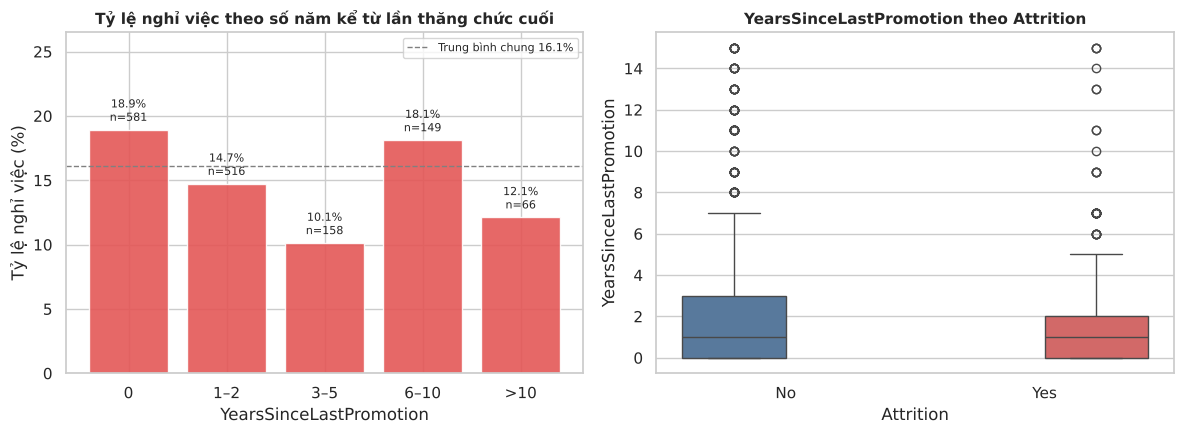

In [31]:
# H4: Thời gian từ lần thăng chức gần nhất
df_clean["PromoGroup"] = pd.cut(df_clean["YearsSinceLastPromotion"], [-1, 0, 2, 5, 10, 50], labels=["0", "1–2", "3–5", "6–10", ">10"])
g_pr = attr_rate(df_clean, "PromoGroup")
print(g_pr.round(2))
store_rates("PromoGroup", g_pr)
t = test_num(df_clean, "YearsSinceLastPromotion")
print(f"\nMann-Whitney U: {t['note']} | p = {t['p_value']:.3f} | |r| = {t['effect']:.3f} | Bonferroni p = {min(t['p_value'] * m_tests, 1):.3f}")
# YearsInCurrentRole và YearsWithCurrManager để đối chiếu (cũng là các biến 'đứng yên' trong sự nghiệp)
for c in ["YearsInCurrentRole", "YearsWithCurrManager"]:
    tt = test_num(df_clean, c); print(f"{c:22s}: {tt['note']} | p = {tt['p_value']:.2e} | |r| = {tt['effect']:.3f}")
R["H4"] = {"p": float(t["p_value"]), "r": float(t["effect"]), "note": t["note"]}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
bar_rate(ax[0], g_pr, "Tỷ lệ nghỉ việc theo số năm kể từ lần thăng chức cuối", "YearsSinceLastPromotion")
sns.boxplot(data=df_clean, x="Attrition", y="YearsSinceLastPromotion", hue="Attrition", order=["No", "Yes"], palette={"No": C_NO, "Yes": C_YES}, legend=False, ax=ax[1])
ax[1].set_title("YearsSinceLastPromotion theo Attrition", fontsize=11)
plt.tight_layout(); save_fig("fig09_promotion.png"); plt.show()

## 3.7 H5 – Mức độ hài lòng và cân bằng công việc – cuộc sống

**Khung kiểm định 5 bước**

| Bước | Nội dung |
|---|---|
| 1. Cặp giả thuyết | **H₀:** tỷ lệ nghỉ việc độc lập với từng mức hài lòng/gắn kết (JobSatisfaction, EnvironmentSatisfaction, WorkLifeBalance, JobInvolvement).<br>**H₁:** tỷ lệ nghỉ việc khác nhau giữa các mức (kỳ vọng: mức thấp nghỉ nhiều hơn). |
| 2. Dữ liệu và giả định | Bốn biến thứ bậc thang 1–4 → bảng chéo 4×2; tần số kỳ vọng đều ≥ 5. |
| 3. Kiểm định | Chi-square độc lập + Cramér's V cho từng biến; Spearman ρ để xem quan hệ có đơn điệu không. |
| 4. Tính toán | Thống kê kiểm định, p-value, effect size (ô code bên dưới); p hiệu chỉnh Bonferroni lấy từ mục 3.2 |
| 5. Quy tắc kết luận | Bác bỏ H₀ nếu p sau hiệu chỉnh Bonferroni < 0,05; đọc kèm effect size và chênh lệch tỷ lệ để đánh giá ý nghĩa thực tế. |


JobSatisfaction         : chi2 = 17.5, p = 5.56e-04, V = 0.109 | Spearman rho = -0.103 (p = 7.7e-05)
   tỷ lệ nghỉ việc (%): {1: 22.8, 2: 16.4, 3: 16.5, 4: 11.3} | n: {1: 289, 2: 280, 3: 442, 4: 459}
WorkLifeBalance         : chi2 = 16.3, p = 9.73e-04, V = 0.105 | Spearman rho = -0.052 (p = 4.6e-02)
   tỷ lệ nghỉ việc (%): {1: 31.2, 2: 16.9, 3: 14.2, 4: 17.6} | n: {1: 80, 2: 344, 3: 893, 4: 153}
EnvironmentSatisfaction : chi2 = 22.5, p = 5.12e-05, V = 0.124 | Spearman rho = -0.096 (p = 2.1e-04)
   tỷ lệ nghỉ việc (%): {1: 25.4, 2: 15.0, 3: 13.7, 4: 13.5} | n: {1: 284, 2: 287, 3: 453, 4: 446}
JobInvolvement          : chi2 = 28.5, p = 2.86e-06, V = 0.139 | Spearman rho = -0.119 (p = 4.3e-06)
   tỷ lệ nghỉ việc (%): {1: 33.7, 2: 18.9, 3: 14.4, 4: 9.0} | n: {1: 83, 2: 375, 3: 868, 4: 144}


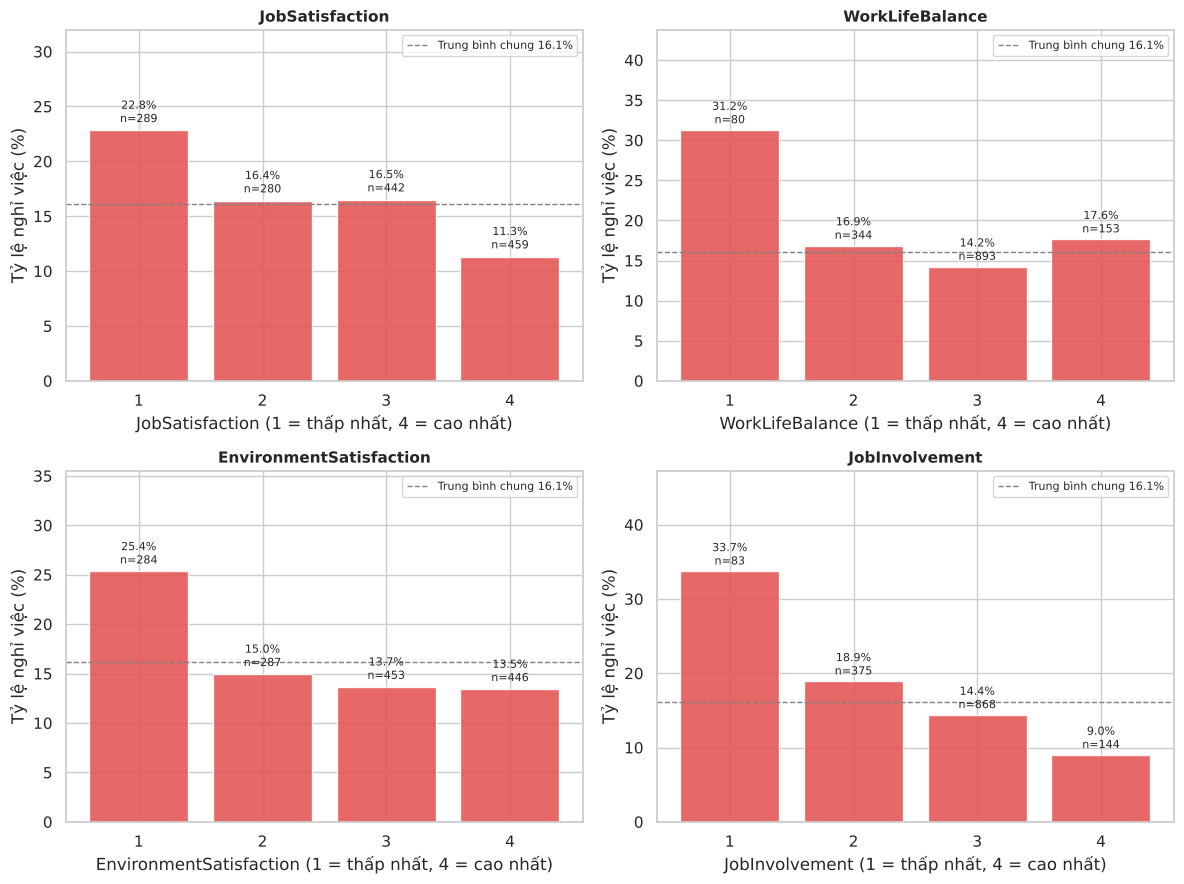

In [32]:
# H5: Các biến thang điểm 1-4: tỷ lệ nghỉ việc theo từng mức và hệ số tương quan hạng Spearman
sat_vars = ["JobSatisfaction", "WorkLifeBalance", "EnvironmentSatisfaction", "JobInvolvement"]
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
R["H5"] = {}
for a, c in zip(ax.ravel(), sat_vars):
    g = attr_rate(df_clean, c)
    bar_rate(a, g, f"{c}", f"{c} (1 = thấp nhất, 4 = cao nhất)")
    t = test_cat(df_clean, c)
    rho, p_rho = stats.spearmanr(df_clean[c], df_clean["AttritionFlag"])
    print(f"{c:24s}: chi2 = {t['statistic']:.1f}, p = {t['p_value']:.2e}, V = {t['effect']:.3f} | Spearman rho = {rho:.3f} (p = {p_rho:.1e})")
    print("   tỷ lệ nghỉ việc (%):", g["rate"].round(1).to_dict(), "| n:", g["n"].to_dict())
    store_rates(c, g)
    R["H5"][c] = {"chi2": float(t["statistic"]), "p": float(t["p_value"]), "V": float(t["effect"]), "rho": float(rho)}
plt.tight_layout(); save_fig("fig10_satisfaction.png"); plt.show()

## 3.8 H6 – Quyền chọn cổ phiếu (`StockOptionLevel`)

**Khung kiểm định 5 bước**

| Bước | Nội dung |
|---|---|
| 1. Cặp giả thuyết | **H₀:** tỷ lệ nghỉ việc độc lập với mức quyền chọn cổ phiếu.<br>**H₁:** tỷ lệ nghỉ việc khác nhau giữa các mức (kỳ vọng: không có cổ phiếu nghỉ nhiều hơn). |
| 2. Dữ liệu và giả định | `StockOptionLevel` thứ bậc 0–3 → bảng chéo 4×2. Nghi vấn nhiễu: toàn bộ nhân viên độc thân có mức 0. |
| 3. Kiểm định | Chi-square + Cramér's V; bảng chéo với MaritalStatus; kiểm định CMH trong nhóm Married/Divorced (mục H6b). |
| 4. Tính toán | Thống kê kiểm định, p-value, effect size (ô code bên dưới); p hiệu chỉnh Bonferroni lấy từ mục 3.2 |
| 5. Quy tắc kết luận | Bác bỏ H₀ nếu p sau hiệu chỉnh Bonferroni < 0,05; đọc kèm effect size và chênh lệch tỷ lệ để đánh giá ý nghĩa thực tế. |


                   rate    n  left
StockOptionLevel                  
0                 24.41  631   154
1                  9.40  596    56
2                  7.59  158    12
3                 17.65   85    15

Chi-square = 60.6, p = 4.38e-13, V = 0.203

Cơ cấu tình trạng hôn nhân theo StockOptionLevel (% theo hàng):
MaritalStatus     Divorced  Married  Single
StockOptionLevel                           
0                      1.3     24.2    74.5
1                     32.7     67.3     0.0
2                     47.5     52.5     0.0
3                     57.6     42.4     0.0

Tỷ lệ nghỉ việc (%) theo MaritalStatus × StockOptionLevel:
StockOptionLevel     0    1    2     3
MaritalStatus                         
Divorced          37.5  9.2  6.7  14.3
Married           20.3  9.5  8.4  22.2
Single            25.5  NaN  NaN   NaN

Cỡ mẫu:
StockOptionLevel      0      1     2     3
MaritalStatus                             
Divorced            8.0  195.0  75.0  49.0
Married           153.0 

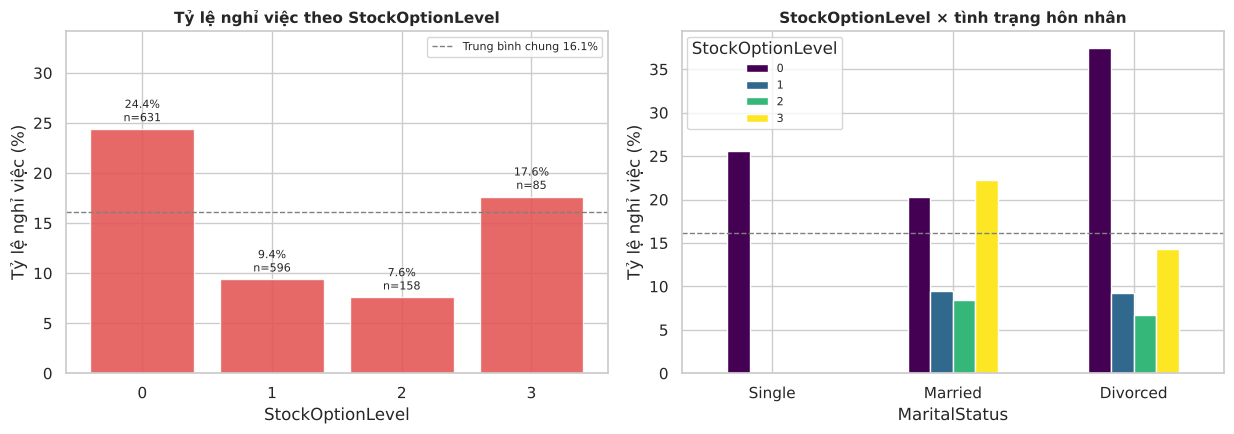

In [33]:
# H6: StockOptionLevel – kiểm tra cả nguy cơ nhiễu từ tình trạng hôn nhân
g_so = attr_rate(df_clean, "StockOptionLevel")
print(g_so.round(2)); store_rates("StockOptionLevel", g_so)
t = test_cat(df_clean, "StockOptionLevel")
print(f"\nChi-square = {t['statistic']:.1f}, p = {t['p_value']:.2e}, V = {t['effect']:.3f}")
print("\nCơ cấu tình trạng hôn nhân theo StockOptionLevel (% theo hàng):")
mx = pd.crosstab(df_clean["StockOptionLevel"], df_clean["MaritalStatus"], normalize="index") * 100
print(mx.round(1))
so_m = df_clean.groupby(["MaritalStatus", "StockOptionLevel"], observed=True)["AttritionFlag"].agg(rate="mean", n="size")
so_m["rate"] *= 100
print("\nTỷ lệ nghỉ việc (%) theo MaritalStatus × StockOptionLevel:"); print(so_m["rate"].unstack().round(1))
print("\nCỡ mẫu:"); print(so_m["n"].unstack())
R["H6"] = {"chi2": float(t["statistic"]), "p": float(t["p_value"]), "V": float(t["effect"]),
           "single_pct_lvl0": float(mx.loc[0, "Single"]), "single_pct_lvl1": float(mx.loc[1, "Single"])}

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.5))
bar_rate(ax[0], g_so, "Tỷ lệ nghỉ việc theo StockOptionLevel", "StockOptionLevel")
so_m["rate"].unstack().loc[["Single", "Married", "Divorced"]].plot.bar(ax=ax[1], rot=0, edgecolor="white", colormap="viridis")
ax[1].axhline(overall, ls="--", color="gray", lw=1)
ax[1].set_title("StockOptionLevel × tình trạng hôn nhân", fontsize=11); ax[1].set_ylabel("Tỷ lệ nghỉ việc (%)"); ax[1].legend(title="StockOptionLevel", fontsize=8)
plt.tight_layout(); save_fig("fig11_stock_option.png"); plt.show()

In [34]:
# H6b: Kiểm định CMH – không có cổ phiếu (StockOptionLevel = 0) so với có (>= 1), phân tầng theo MaritalStatus.
# Chỉ dùng nhóm Married và Divorced vì KHÔNG có nhân viên độc thân nào có cổ phiếu (tầng Single không so sánh được).
d_ns = df_clean[df_clean["MaritalStatus"] != "Single"].copy()
d_ns["MaritalStatus"] = d_ns["MaritalStatus"].astype(str)
r = cmh_test(d_ns, d_ns["StockOptionLevel"] == 0, "MaritalStatus")
print(f"Nhóm Married + Divorced (n = {len(d_ns)}): OR gộp (không có cổ phiếu so với có) = {r['OR_pooled']:.2f} "
      f"(KTC 95%: {r['OR_lo']:.2f} – {r['OR_hi']:.2f}) | p CMH = {r['p_cmh']:.1e} | p Breslow–Day = {r['p_breslow_day']:.2f}")
R.setdefault("CMH", {})["StockOption0|MaritalStatus(non-single)"] = r

Nhóm Married + Divorced (n = 1000): OR gộp (không có cổ phiếu so với có) = 2.40 (KTC 95%: 1.51 – 3.81) | p CMH = 1.4e-04 | p Breslow–Day = 0.22


**Nhận xét H6b:** trong nhóm đã kết hôn hoặc ly hôn (1.000 người), nhân viên không có quyền chọn cổ phiếu có odds nghỉ việc cao gấp **2,40 lần** (KTC 95%: 1,51–3,81; p = 1,4×10⁻⁴), và hiệu ứng đồng nhất giữa hai nhóm (Breslow–Day p = 0,22). Như vậy liên hệ giữa cổ phiếu và nghỉ việc **vẫn tồn tại khi đã loại nhóm độc thân**, không chỉ là hệ quả của hôn nhân. Với nhân viên độc thân thì dữ liệu không trả lời được (không ai có cổ phiếu), nên đề xuất thí điểm cổ phiếu cho nhóm này phải có nhóm đối chứng.

## 3.9 H7 – Công tác, tình trạng hôn nhân và khoảng cách đi làm

**Khung kiểm định 5 bước**

| Bước | Nội dung |
|---|---|
| 1. Cặp giả thuyết | **H₀:** tỷ lệ nghỉ việc độc lập với mức đi công tác và tình trạng hôn nhân; khoảng cách đi làm có phân phối như nhau ở hai nhóm.<br>**H₁:** có khác biệt (kỳ vọng: công tác thường xuyên, độc thân, ở xa thì nghỉ nhiều hơn). |
| 2. Dữ liệu và giả định | `BusinessTravel` (3 mức), `MaritalStatus` (3 nhóm) là biến phân loại; `DistanceFromHome` là biến số 1–29 km, không chuẩn. |
| 3. Kiểm định | Chi-square + Cramér's V cho hai biến phân loại; Mann–Whitney U hai phía + |r| cho khoảng cách. |
| 4. Tính toán | Thống kê kiểm định, p-value, effect size (ô code bên dưới); p hiệu chỉnh Bonferroni lấy từ mục 3.2 |
| 5. Quy tắc kết luận | Bác bỏ H₀ nếu p sau hiệu chỉnh Bonferroni < 0,05; đọc kèm effect size và chênh lệch tỷ lệ để đánh giá ý nghĩa thực tế. So thêm với FDR vì khoảng cách nằm sát ngưỡng. |


                    rate     n  left
BusinessTravel                      
Non-Travel          8.00   150    12
Travel_Rarely      14.96  1043   156
Travel_Frequently  24.91   277    69

                rate    n  left
MaritalStatus                  
Single         25.53  470   120
Married        12.48  673    84
Divorced       10.09  327    33

                rate    n  left
DistanceGroup                  
1–5 km         13.77  632    87
6–10 km        14.47  394    57
11–20 km       20.00  240    48
21–29 km       22.06  204    45

BusinessTravel : chi2 = 24.2, p = 5.61e-06, V = 0.128
MaritalStatus  : chi2 = 46.2, p = 9.46e-11, V = 0.177
DistanceFromHome: trung vị Yes = 9 | No = 7 | p = 2.39e-03 | |r| = 0.124


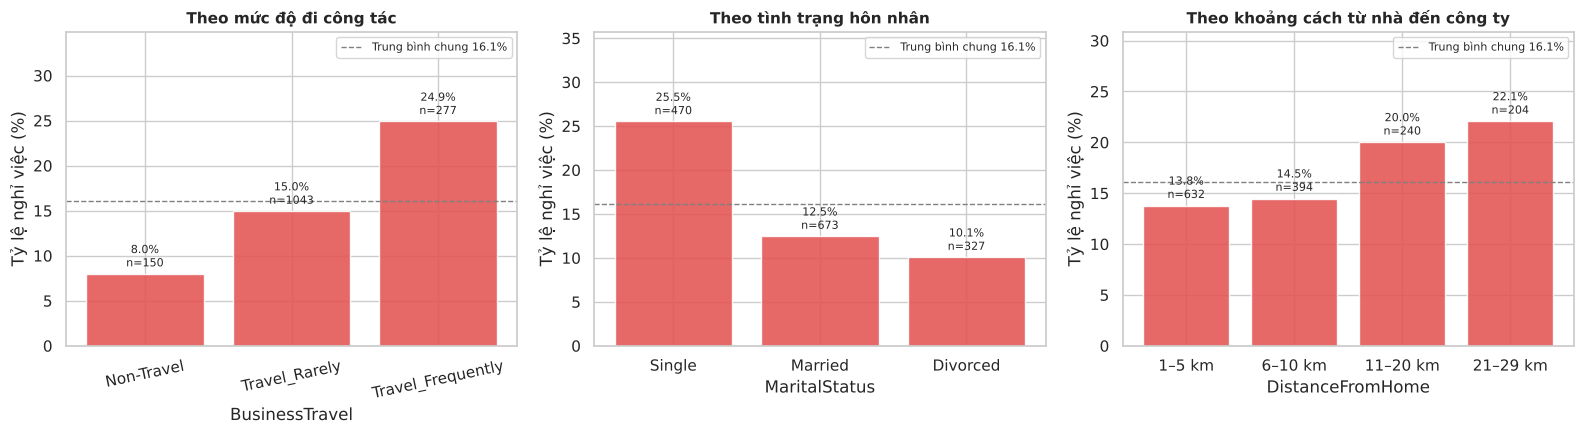

In [35]:
# H7: BusinessTravel, MaritalStatus, DistanceFromHome
df_clean["DistanceGroup"] = pd.cut(df_clean["DistanceFromHome"], [0, 5, 10, 20, 30], labels=["1–5 km", "6–10 km", "11–20 km", "21–29 km"])
g_bt = attr_rate(df_clean, "BusinessTravel").loc[["Non-Travel", "Travel_Rarely", "Travel_Frequently"]]
g_ms = attr_rate(df_clean, "MaritalStatus").loc[["Single", "Married", "Divorced"]]
g_ds = attr_rate(df_clean, "DistanceGroup")
for name, g in [("BusinessTravel", g_bt), ("MaritalStatus", g_ms), ("DistanceGroup", g_ds)]:
    print(g.round(2)); print(); store_rates(name, g)
R["H7"] = {}
for c in ["BusinessTravel", "MaritalStatus"]:
    t = test_cat(df_clean, c); print(f"{c:15s}: chi2 = {t['statistic']:.1f}, p = {t['p_value']:.2e}, V = {t['effect']:.3f}")
    R["H7"][c] = {"chi2": float(t["statistic"]), "p": float(t["p_value"]), "V": float(t["effect"])}
t = test_num(df_clean, "DistanceFromHome"); print(f"DistanceFromHome: {t['note']} | p = {t['p_value']:.2e} | |r| = {t['effect']:.3f}")
R["H7"]["DistanceFromHome"] = {"p": float(t["p_value"]), "r": float(t["effect"]), "note": t["note"]}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
bar_rate(ax[0], g_bt, "Theo mức độ đi công tác", "BusinessTravel", rot=12)
bar_rate(ax[1], g_ms, "Theo tình trạng hôn nhân", "MaritalStatus")
bar_rate(ax[2], g_ds, "Theo khoảng cách từ nhà đến công ty", "DistanceFromHome")
plt.tight_layout(); save_fig("fig12_travel_marital_distance.png"); plt.show()

## 3.10 H8 – Vị trí công việc và phòng ban

**Khung kiểm định 5 bước**

| Bước | Nội dung |
|---|---|
| 1. Cặp giả thuyết | **H₀:** tỷ lệ nghỉ việc như nhau giữa các vị trí công việc (và giữa các phòng ban).<br>**H₁:** tỷ lệ nghỉ việc khác nhau giữa các vị trí (và phòng ban). |
| 2. Dữ liệu và giả định | `JobRole` 9 nhóm → bảng 9×2; `Department` 3 nhóm → bảng 3×2; JobRole lồng trong Department. |
| 3. Kiểm định | Chi-square + Cramér's V cho từng biến. |
| 4. Tính toán | Thống kê kiểm định, p-value, effect size (ô code bên dưới); p hiệu chỉnh Bonferroni lấy từ mục 3.2 |
| 5. Quy tắc kết luận | Bác bỏ H₀ nếu p sau hiệu chỉnh Bonferroni < 0,05; đọc kèm effect size và chênh lệch tỷ lệ để đánh giá ý nghĩa thực tế. |


                            rate    n  left
JobRole                                    
Research Director           2.50   80     2
Manager                     4.90  102     5
Healthcare Representative   6.87  131     9
Manufacturing Director      6.90  145    10
Research Scientist         16.10  292    47
Sales Executive            17.48  326    57
Human Resources            23.08   52    12
Laboratory Technician      23.94  259    62
Sales Representative       39.76   83    33

                         rate    n  left
Department                              
Research & Development  13.84  961   133
Human Resources         19.05   63    12
Sales                   20.63  446    92

JobRole: chi2 = 86.2, p = 2.75e-15, V = 0.242, min tần số kỳ vọng = 8.4

Department: chi2 = 10.8, p = 4.53e-03, V = 0.086, min tần số kỳ vọng = 10.2


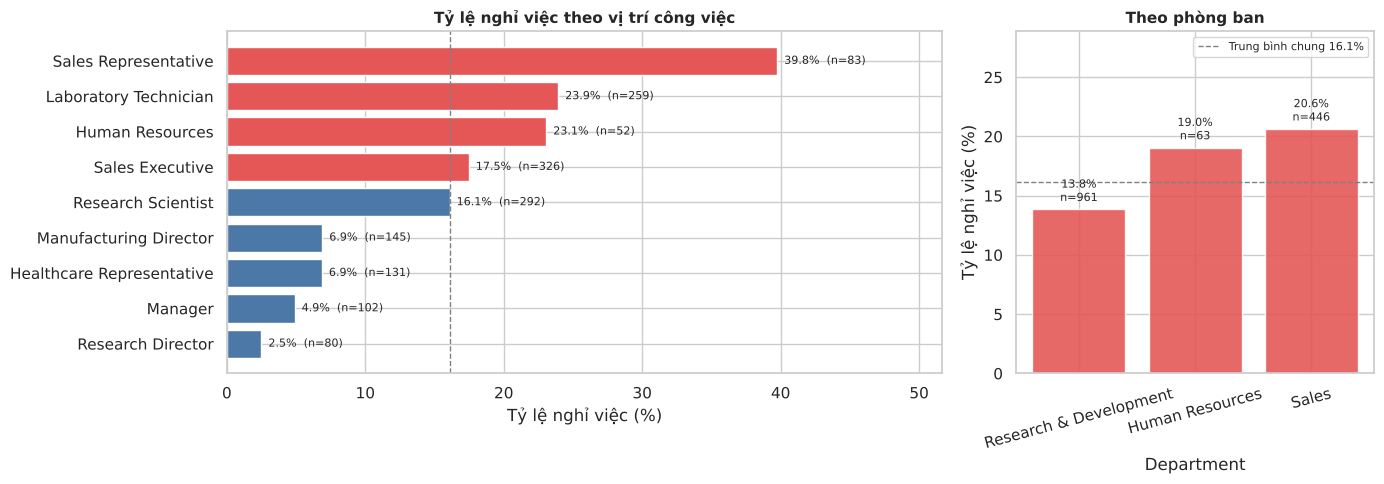

In [36]:
# H8: JobRole và Department
g_jr = attr_rate(df_clean, "JobRole").sort_values("rate")
g_dp = attr_rate(df_clean, "Department").sort_values("rate")
print(g_jr.round(2)); print(); print(g_dp.round(2))
store_rates("JobRole", g_jr); store_rates("Department", g_dp)
R["H8"] = {}
for c in ["JobRole", "Department"]:
    t = test_cat(df_clean, c); print(f"\n{c}: chi2 = {t['statistic']:.1f}, p = {t['p_value']:.2e}, V = {t['effect']:.3f}, {t['note']}")
    R["H8"][c] = {"chi2": float(t["statistic"]), "p": float(t["p_value"]), "V": float(t["effect"])}

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
ax[0].barh(g_jr.index.astype(str), g_jr["rate"], color=[C_YES if r > overall else C_NO for r in g_jr["rate"]])
for i, (r, n) in enumerate(zip(g_jr["rate"], g_jr["n"])):
    ax[0].text(r + 0.5, i, f"{r:.1f}%  (n={n})", va="center", fontsize=8)
ax[0].axvline(overall, ls="--", color="gray", lw=1); ax[0].set_xlim(0, g_jr["rate"].max() * 1.3)
ax[0].set_title("Tỷ lệ nghỉ việc theo vị trí công việc", fontsize=11); ax[0].set_xlabel("Tỷ lệ nghỉ việc (%)")
bar_rate(ax[1], g_dp, "Theo phòng ban", "Department", rot=15)
plt.tight_layout(); save_fig("fig13_jobrole_department.png"); plt.show()

**Nhận xét H8 – xếp hạng đầy đủ 9 vị trí** (tỷ lệ nghỉ việc, số người nghỉ / tổng số):

| Hạng | Vị trí | Tỷ lệ nghỉ | Nghỉ / tổng | So với mức chung 16,1% |
|---|---|---|---|---|
| 1 | Sales Representative | 39,8% | 33 / 83 | gấp 2,5 lần |
| 2 | Laboratory Technician | 23,9% | 62 / 259 | gấp 1,5 lần |
| 3 | Human Resources | 23,1% | 12 / 52 | gấp 1,4 lần |
| 4 | Sales Executive | 17,5% | 57 / 326 | xấp xỉ mức chung |
| 5 | Research Scientist | 16,1% | 47 / 292 | bằng mức chung |
| 6 | Manufacturing Director | 6,9% | 10 / 145 | thấp hơn |
| 7 | Healthcare Representative | 6,9% | 9 / 131 | thấp hơn |
| 8 | Manager | 4,9% | 5 / 102 | thấp hơn |
| 9 | Research Director | 2,5% | 2 / 80 | thấp nhất |

- **Hai nhóm rõ rệt:** 5 vị trí tuyến đầu/chuyên viên (16–40%) và 4 vị trí quản lý/chuyên gia cấp cao (2,5–7%). Chênh lệch giữa cao nhất và thấp nhất là 37 điểm phần trăm (khoảng 16 lần).
- **Tỷ lệ khác với số tuyệt đối:** Sales Representative có tỷ lệ cao nhất nhưng chỉ 33 người nghỉ; ba vị trí Laboratory Technician, Sales Executive, Research Scientist chiếm 166/237 = 70% số người nghỉ vì quy mô lớn. Chính sách cần cả hai hướng: can thiệp sâu cho Sales Representative và can thiệp diện rộng cho ba vị trí đông người.
- **Cỡ mẫu nhỏ:** Human Resources (52 người) và Sales Representative (83 người) có khoảng tin cậy rộng; xếp hạng 2–3 và 6–7 gần như ngang nhau.
- **Phòng ban:** Sales 20,6%, Human Resources 19,0%, R&D 13,8%, nhưng không có ý nghĩa sau Bonferroni (p = 0,14). Mỗi phòng ban trộn vị trí rủi ro cao với vị trí rủi ro thấp (ví dụ phòng Sales có cả Sales Representative 39,8% và Manager), nên chính sách nên thiết kế **theo vị trí** thay vì theo phòng ban.

## 3.10b H0* – Đối chứng: giới tính

**Khung kiểm định 5 bước**

| Bước | Nội dung |
|---|---|
| 1. Cặp giả thuyết | **H₀:** tỷ lệ nghỉ việc độc lập với giới tính.<br>**H₁:** tỷ lệ nghỉ việc khác nhau giữa nam và nữ. |
| 2. Dữ liệu và giả định | `Gender` nhị phân → bảng 2×2. Đây là **biến đối chứng**: không có lý do nghiệp vụ mạnh để giới tính ảnh hưởng, nên kỳ vọng *không bác bỏ* H₀. Nếu bác bỏ, cần nghi ngờ quy trình (ví dụ đang "câu" p-value). |
| 3. Kiểm định | Chi-square độc lập + Cramér's V; odds ratio kèm KTC 95%. |
| 4. Tính toán | Thống kê kiểm định, p-value, effect size (ô code bên dưới); p hiệu chỉnh Bonferroni lấy từ mục 3.2 |
| 5. Quy tắc kết luận | Kỳ vọng p ≥ 0,05; đối chiếu với p sau Bonferroni. |


In [37]:
# H0*: Kiểm định đối chứng – Gender và Attrition
g_gd = attr_rate(df_clean, "Gender")
print(g_gd.round(2)); store_rates("Gender", g_gd)
t = test_cat(df_clean, "Gender")
ct_g = pd.crosstab(df_clean["Gender"], df_clean["Attrition"])
or_g, or_g_lo, or_g_hi = odds_ratio(ct_g.loc["Male", "Yes"], ct_g.loc["Male", "No"], ct_g.loc["Female", "Yes"], ct_g.loc["Female", "No"])
print(f"\nChi-square = {t['statistic']:.2f}, p = {t['p_value']:.3f}, p Bonferroni = {min(t['p_value'] * m_tests, 1):.3f}, Cramér's V = {t['effect']:.3f}")
print(f"Odds ratio (Nam so với Nữ) = {or_g:.2f} (KTC 95%: {or_g_lo:.2f} – {or_g_hi:.2f})")
R["H0_gender"] = {"chi2": float(t["statistic"]), "p": float(t["p_value"]), "V": float(t["effect"]), "OR": float(or_g), "OR_lo": float(or_g_lo), "OR_hi": float(or_g_hi)}

         rate    n  left
Gender                  
Female  14.80  588    87
Male    17.01  882   150

Chi-square = 1.28, p = 0.259, p Bonferroni = 1.000, Cramér's V = 0.029
Odds ratio (Nam so với Nữ) = 1.18 (KTC 95%: 0.89 – 1.57)


**Nhận xét H0*:** nữ nghỉ việc 14,8% (87/588), nam 17,0% (150/882); chênh lệch 2,2 điểm phần trăm, p = 0,26 (chưa hiệu chỉnh; sau Bonferroni = 1,00), Cramér's V = 0,03, odds ratio nam so với nữ = 1,18 (KTC 95%: 0,89–1,57). Khoảng tin cậy của odds ratio chứa 1 nên **không bác bỏ H₀**, đúng như kỳ vọng của biến đối chứng. Kết quả này giúp tăng độ tin cậy cho quy trình: các kiểm định không "tìm ra" liên hệ ở nơi không có lý do để có. Về chính sách, không cần thiết kế chương trình giữ chân riêng theo giới tính.

## 3.11 Ma trận tương quan (Heatmap)

Dùng hệ số **Spearman** (không giả định tuyến tính hay phân phối chuẩn, phù hợp với biến thứ bậc và biến lệch), gồm biến số, biến thang điểm, `OverTime` và biến mục tiêu `AttritionFlag`.

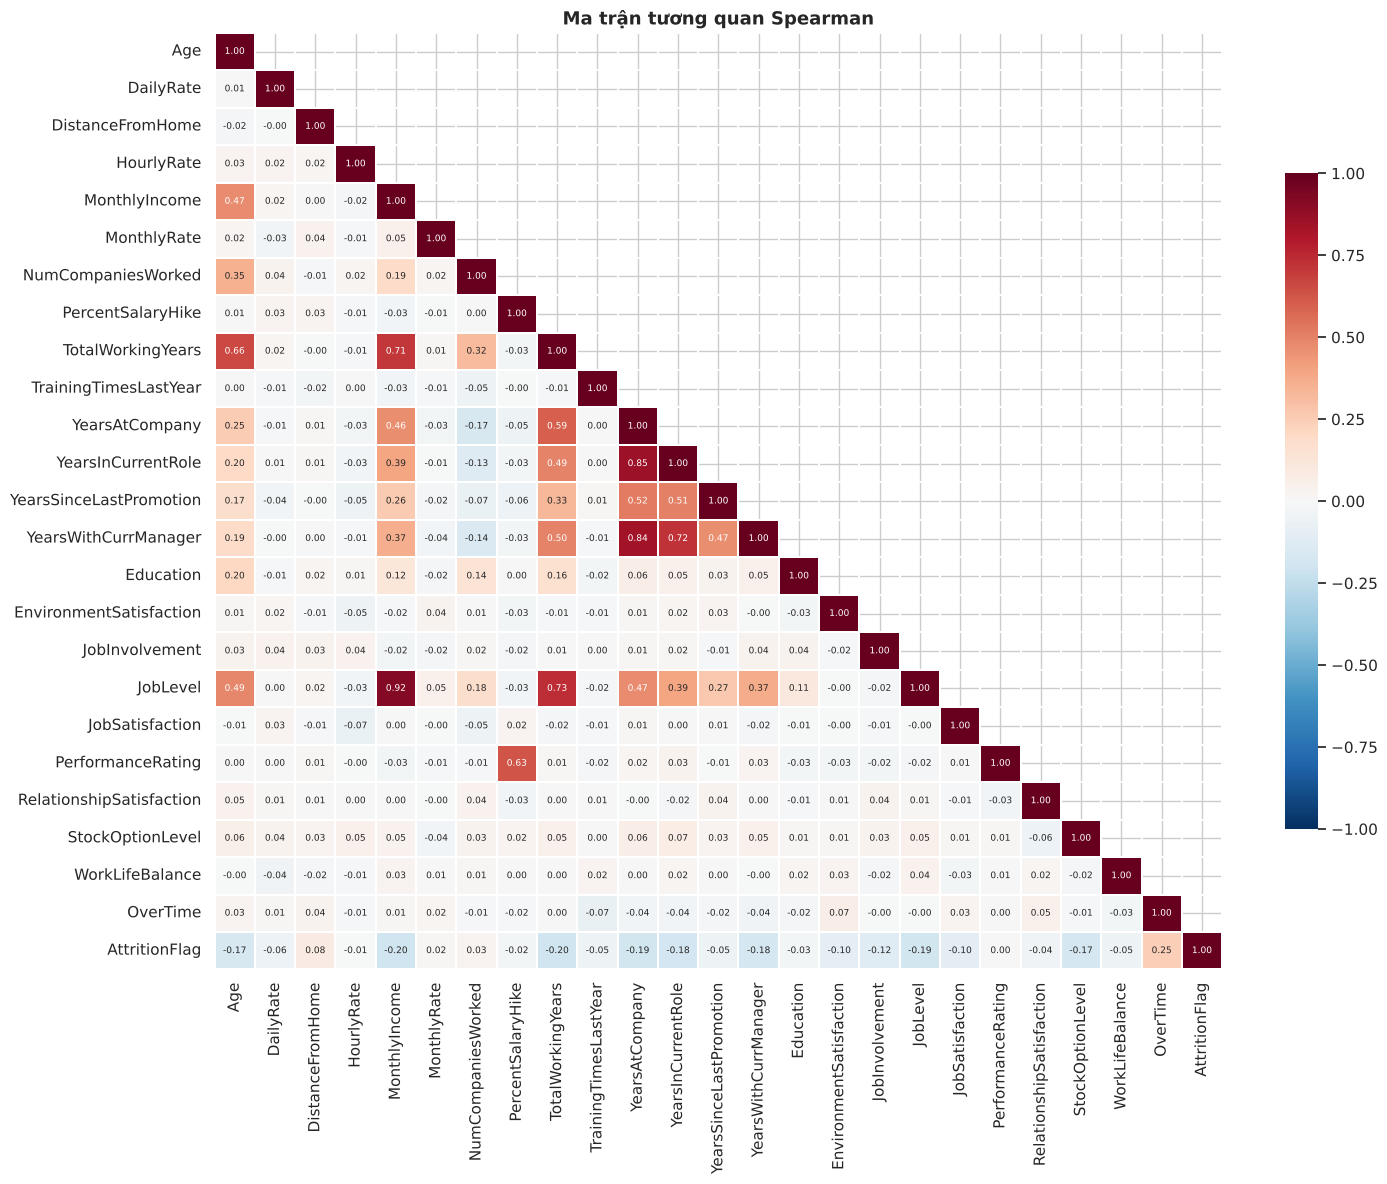

Top 10 tương quan (Spearman) với Attrition:
OverTime                0.246
TotalWorkingYears      -0.199
MonthlyIncome          -0.198
YearsAtCompany         -0.190
JobLevel               -0.190
YearsInCurrentRole     -0.181
YearsWithCurrManager   -0.175
StockOptionLevel       -0.172
Age                    -0.171
JobInvolvement         -0.119
Name: AttritionFlag, dtype: float64

Các cặp biến có |rho| >= 0.7:
   JobLevel – MonthlyIncome: 0.92
   YearsInCurrentRole – YearsAtCompany: 0.85
   YearsWithCurrManager – YearsAtCompany: 0.84
   JobLevel – TotalWorkingYears: 0.73
   YearsWithCurrManager – YearsInCurrentRole: 0.72
   TotalWorkingYears – MonthlyIncome: 0.71


In [38]:
# 3.11 Heatmap tương quan Spearman
corr_cols = CONT_COLS + ORDINAL_COLS
df_corr = df_clean[corr_cols].copy()
df_corr["OverTime"] = (df_clean["OverTime"] == "Yes").astype(int)
df_corr["AttritionFlag"] = df_clean["AttritionFlag"]
corr = df_corr.corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6.5},
            linewidths=0.3, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Ma trận tương quan Spearman", fontsize=13)
plt.tight_layout(); save_fig("fig14_correlation_heatmap.png"); plt.show()

# Tương quan với Attrition và các cặp biến tương quan mạnh (nguy cơ đa cộng tuyến)
corr_attr = corr["AttritionFlag"].drop("AttritionFlag").sort_values(key=np.abs, ascending=False)
print("Top 10 tương quan (Spearman) với Attrition:"); print(corr_attr.head(10).round(3))
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[:i] if abs(corr.loc[a, b]) >= 0.7]
pairs = sorted(pairs, key=lambda x: -abs(x[2]))
print("\nCác cặp biến có |rho| >= 0.7:")
for a, b, r in pairs:
    print(f"   {a} – {b}: {r:.2f}")
R["corr_top"] = {k: float(v) for k, v in corr_attr.head(10).items()}
R["corr_pairs"] = [{"a": a, "b": b, "r": float(r)} for a, b, r in pairs]

## 3.12 Mô hình tham chiếu: hồi quy logistic (kiểm chứng đa biến)

Các kiểm định ở trên xét từng biến riêng lẻ nên có thể bị **yếu tố nhiễu** (ví dụ thu nhập phụ thuộc cấp bậc và tuổi). Một mô hình hồi quy logistic dùng đồng thời nhiều biến cho biết biến nào còn liên hệ với nghỉ việc **khi các biến khác được giữ cố định**. Đây là mô hình tham chiếu để diễn giải, không phải mô hình triển khai thực tế.

- **3.12a – Kiểm tra đa cộng tuyến (VIF)** trước khi chọn biến đưa vào mô hình.
- Chia train/test 80/20 có phân tầng (`stratify`) để giữ tỷ lệ nghỉ việc.
- `RobustScaler` chỉ `fit` trên tập train (trong `Pipeline` nên cũng không rò rỉ khi cross-validation).
- `class_weight="balanced"` để xử lý mất cân bằng lớp; đánh giá bằng ROC-AUC, PR-AUC, recall, precision thay vì accuracy.
- Độ ổn định: ngoài một lần chia train/test, dùng **5-fold CV lặp lại 10 lần** để có khoảng dao động của AUC.
- Để so sánh được các hệ số có đơn vị khác nhau (biến liên tục theo IQR, thang điểm theo 1 mức, nhị phân 0/1), biểu đồ dùng **hệ số chuẩn hóa** = hệ số × độ lệch chuẩn của đặc trưng (tác động khi đặc trưng tăng 1 SD).


In [39]:
# 3.12a Kiểm tra đa cộng tuyến bằng VIF (Variance Inflation Factor); VIF > 10 là đa cộng tuyến nghiêm trọng
def vif_table(X):
    # Chuẩn hóa (trừ trung bình) để VIF tương đương mô hình có hệ số chặn
    Xs = (X - X.mean()) / X.std()
    return pd.Series([variance_inflation_factor(Xs.values, k) for k in range(Xs.shape[1])], index=X.columns)

X_all = df_model.drop(columns=["AttritionFlag"])
DEPT_COLS = [c for c in X_all.columns if c.startswith("Department_")]
vif_all, vif_nodept = vif_table(X_all), vif_table(X_all.drop(columns=DEPT_COLS))
vif_cmp = pd.DataFrame({"VIF_du_bien": vif_all, "VIF_bo_Department": vif_nodept}).sort_values("VIF_du_bien", ascending=False)
display(vif_cmp.head(10).round(1))

# Bằng chứng JobRole lồng trong Department: mỗi JobRole thuộc bao nhiêu phòng ban?
nest = df_clean.groupby("JobRole", observed=True)["Department"].nunique()
print("Số phòng ban của mỗi JobRole:", nest.to_dict())
print(f"VIF lớn nhất: đủ biến = {vif_all.max():.1f} | bỏ Department = {vif_nodept.max():.1f}")
R["vif"] = {"max_all": float(vif_all.max()), "max_nodept": float(vif_nodept.max()),
            "top_all": vif_all.sort_values(ascending=False).head(5).round(1).to_dict(),
            "top_nodept": vif_nodept.sort_values(ascending=False).head(5).round(1).to_dict()}

,VIF_du_bien,VIF_bo_Department
Department_Sales,44.1,NaN
Department_Research & Development,43.9,NaN
EducationField_Life Sciences,24.1,20.2
EducationField_Medical,21.6,18.2
JobRole_Sales Executive,14.5,3.1
EducationField_Marketing,10.9,9.1
MonthlyIncome_log,9.1,9.1
EducationField_Technical Degree,8.9,7.6
JobLevel,8.5,8.5
JobRole_Human Resources,7.3,2.0


Số phòng ban của mỗi JobRole: {'Healthcare Representative': 1, 'Human Resources': 1, 'Laboratory Technician': 1, 'Manager': 3, 'Manufacturing Director': 1, 'Research Director': 1, 'Research Scientist': 1, 'Sales Executive': 1, 'Sales Representative': 1}
VIF lớn nhất: đủ biến = 44.1 | bỏ Department = 20.2


**Quyết định:** các cột `Department_*` có VIF rất cao vì `JobRole` lồng trong `Department` (mỗi vị trí chỉ thuộc một phòng ban, riêng Manager có ở cả 3 phòng ban), nên `Department` gần như được suy ra hoàn toàn từ `JobRole`. Giữ cả hai làm hệ số của `JobRole` không ổn định. Mô hình **loại `Department`** và giữ `JobRole` vì `JobRole` chi tiết hơn và có liên hệ mạnh hơn với nghỉ việc (V = 0,24 so với 0,09). Sau khi loại, VIF lớn nhất giảm từ 44,1 xuống 20,2. Các VIF còn cao thuộc hai trường hợp: (1) các cột `EducationField_*` (≈ 8–20) là hệ quả của **nhóm tham chiếu quá nhỏ** (`drop_first` bỏ nhóm "Human Resources" chỉ có 27 người), không phải hai thông tin trùng nhau, và `EducationField` vốn không có ý nghĩa ở mục 3.2; (2) cặp đã biết `JobLevel` – `MonthlyIncome_log` (≈ 9), nên **không đọc riêng hệ số của từng biến trong cặp này** (trong mô hình, `JobLevel` mang dấu dương còn thu nhập mang dấu âm, chỉ là hai biến "chia nhau" cùng một thông tin).

ROC-AUC 5-fold CV (train): 0.836 ± 0.027 | ROC-AUC (test): 0.793 | PR-AUC (test): 0.545 (mức nền 0.160)
Accuracy nếu đoán toàn bộ 'ở lại': 84.0%
              precision    recall  f1-score   support

       Ở lại      0.930     0.806     0.863       247
   Nghỉ việc      0.400     0.681     0.504        47

    accuracy                          0.786       294
   macro avg      0.665     0.743     0.684       294
weighted avg      0.845     0.786     0.806       294

Ma trận nhầm lẫn [hàng = thực tế, cột = dự đoán]:
 [[199  48]
 [ 15  32]]


ROC-AUC 5-fold x 10 lần: trung bình 0.826 | 95% số lần nằm trong [0.778; 0.894]

Top 15 hệ số chuẩn hóa lớn nhất theo trị tuyệt đối (OR_per_1SD = odds thay đổi khi đặc trưng tăng 1 độ lệch chuẩn):


,coef,odds_ratio,coef_std,OR_per_1SD
TotalWorkingYears_log,-0.879,0.415,-0.741,0.477
JobLevel,0.677,1.969,0.739,2.095
OverTime,1.627,5.089,0.738,2.091
NumCompaniesWorked_log,0.821,2.273,0.601,1.824
MonthlyIncome_log,-0.849,0.428,-0.533,0.587
BusinessTravel,0.868,2.383,0.466,1.594
EnvironmentSatisfaction,-0.399,0.671,-0.434,0.648
JobRole_Laboratory Technician,1.121,3.068,0.433,1.542
YearsSinceLastPromotion_log,0.718,2.051,0.420,1.522
JobSatisfaction,-0.358,0.699,-0.397,0.672


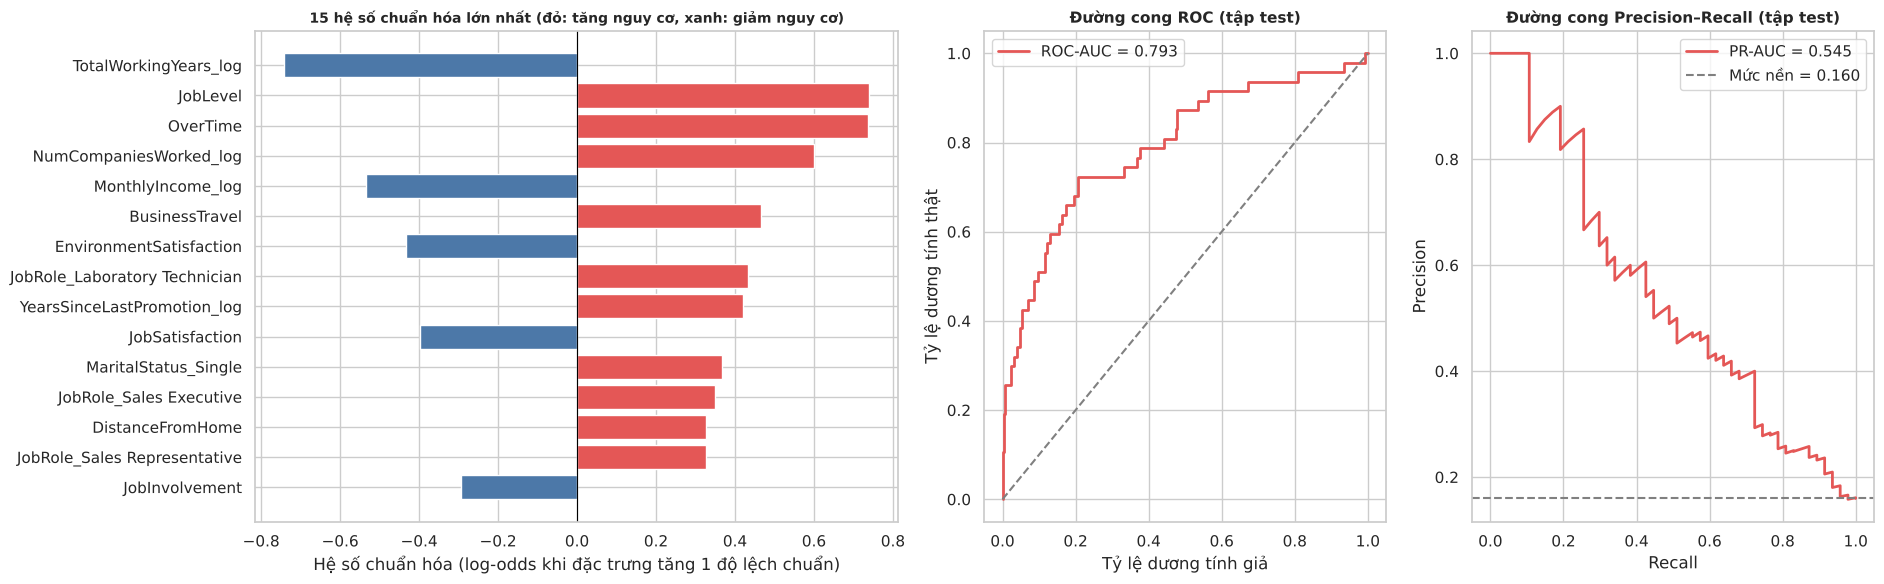

In [40]:
# 3.12b Hồi quy logistic có chuẩn hóa trong Pipeline (đã loại Department theo kết quả VIF)
X = df_model.drop(columns=["AttritionFlag"] + DEPT_COLS); y = df_model["AttritionFlag"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

pre = ColumnTransformer([("scale", RobustScaler(), SCALE_COLS)], remainder="passthrough")
pipe = Pipeline([("pre", pre), ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))])

# (1) CV 5-fold trên tập train + đánh giá trên tập test
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="roc_auc")
pipe.fit(X_tr, y_tr)
proba, pred = pipe.predict_proba(X_te)[:, 1], pipe.predict(X_te)
auc, ap = roc_auc_score(y_te, proba), average_precision_score(y_te, proba)
print(f"ROC-AUC 5-fold CV (train): {cv_auc.mean():.3f} ± {cv_auc.std():.3f} | ROC-AUC (test): {auc:.3f} | PR-AUC (test): {ap:.3f} (mức nền {y_te.mean():.3f})")
print(f"Accuracy nếu đoán toàn bộ 'ở lại': {(1 - y_te.mean()) * 100:.1f}%")
print(classification_report(y_te, pred, target_names=["Ở lại", "Nghỉ việc"], digits=3))
cm = confusion_matrix(y_te, pred); print("Ma trận nhầm lẫn [hàng = thực tế, cột = dự đoán]:\n", cm)
rep = classification_report(y_te, pred, target_names=["stay", "leave"], output_dict=True)

# (2) Độ ổn định: 5-fold CV lặp lại 10 lần trên toàn bộ dữ liệu (50 lần ước lượng AUC)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
rep_auc = cross_val_score(pipe, X, y, cv=rcv, scoring="roc_auc")
lo95, hi95 = np.percentile(rep_auc, [2.5, 97.5])
print(f"ROC-AUC 5-fold x 10 lần: trung bình {rep_auc.mean():.3f} | 95% số lần nằm trong [{lo95:.3f}; {hi95:.3f}]")

# (3) Hệ số: gốc (log-odds theo đơn vị sau tiền xử lý) và CHUẨN HÓA (x độ lệch chuẩn của đặc trưng trên train) để so sánh được
names = [n.split("__", 1)[1] for n in pipe.named_steps["pre"].get_feature_names_out()]
sd = pd.Series(np.asarray(pipe.named_steps["pre"].transform(X_tr), dtype=float).std(axis=0), index=names)
coef = pd.Series(pipe.named_steps["clf"].coef_[0], index=names)
coef_df = pd.DataFrame({"coef": coef, "odds_ratio": np.exp(coef), "coef_std": coef * sd, "OR_per_1SD": np.exp(coef * sd)})
coef_df = coef_df.sort_values("coef_std", key=np.abs, ascending=False)
print("\nTop 15 hệ số chuẩn hóa lớn nhất theo trị tuyệt đối (OR_per_1SD = odds thay đổi khi đặc trưng tăng 1 độ lệch chuẩn):")
display(coef_df.head(15).round(3))
coef_df.to_csv(os.path.join(OUT_DIR, "logreg_coefficients.csv"))
R["model"] = {"cv_auc_mean": float(cv_auc.mean()), "cv_auc_std": float(cv_auc.std()), "test_auc": float(auc), "test_pr_auc": float(ap),
              "rep_cv_auc_mean": float(rep_auc.mean()), "rep_cv_auc_lo95": float(lo95), "rep_cv_auc_hi95": float(hi95),
              "baseline_acc": float((1 - y_te.mean()) * 100), "recall_leave": float(rep["leave"]["recall"]),
              "precision_leave": float(rep["leave"]["precision"]), "f1_leave": float(rep["leave"]["f1-score"]),
              "accuracy": float(rep["accuracy"]), "cm": cm.tolist(), "n_features": int(X.shape[1]), "dropped": DEPT_COLS,
              "top_coef": coef_df.head(15).reset_index().rename(columns={"index": "feature"}).to_dict(orient="records")}

top = coef_df.head(15).iloc[::-1]
fig, ax = plt.subplots(1, 3, figsize=(19, 6), gridspec_kw={"width_ratios": [1.6, 1, 1]})
ax[0].barh(top.index, top["coef_std"], color=[C_YES if v > 0 else C_NO for v in top["coef_std"]])
ax[0].axvline(0, color="black", lw=0.8)
ax[0].set_title("15 hệ số chuẩn hóa lớn nhất (đỏ: tăng nguy cơ, xanh: giảm nguy cơ)", fontsize=10)
ax[0].set_xlabel("Hệ số chuẩn hóa (log-odds khi đặc trưng tăng 1 độ lệch chuẩn)")
fpr, tpr, _ = roc_curve(y_te, proba)
ax[1].plot(fpr, tpr, color=C_YES, lw=2, label=f"ROC-AUC = {auc:.3f}"); ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_title("Đường cong ROC (tập test)", fontsize=11); ax[1].set_xlabel("Tỷ lệ dương tính giả"); ax[1].set_ylabel("Tỷ lệ dương tính thật"); ax[1].legend()
prec, rec, _ = precision_recall_curve(y_te, proba)
ax[2].plot(rec, prec, color=C_YES, lw=2, label=f"PR-AUC = {ap:.3f}")
ax[2].axhline(y_te.mean(), ls="--", color="gray", label=f"Mức nền = {y_te.mean():.3f}")
ax[2].set_title("Đường cong Precision–Recall (tập test)", fontsize=11); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].legend()
plt.tight_layout(); save_fig("fig15_logreg.png"); plt.show()


**Nhận xét mô hình:**

- **Chất lượng xếp hạng:** ROC-AUC trên tập test là 0,793; lặp lại 5-fold CV 10 lần cho trung bình **0,826**, và 95% số lần nằm trong khoảng **0,778–0,894**. Như vậy mức 0,79 trên test chỉ là dao động bình thường do tập test chỉ có 47 ca nghỉ việc. PR-AUC trên test là 0,545, gấp khoảng 3,4 lần mức nền 0,16.
- **Ở ngưỡng mặc định 0,5:** recall lớp nghỉ việc là 0,68, precision là 0,40; accuracy 78,6% thấp hơn mức 84,0% của mô hình đoán "tất cả ở lại", điều này là bình thường khi đã cân bằng lớp.
- **Hệ số chuẩn hóa (so sánh được giữa các biến):** ba yếu tố lớn nhất gần như ngang nhau: `OverTime` (OR ≈ 2,09 cho mỗi 1 SD), `TotalWorkingYears_log` (OR ≈ 0,48, càng nhiều năm đi làm càng ít nghỉ) và `JobLevel` (OR ≈ 2,10). Tiếp theo là số công ty đã làm, thu nhập, mức độ đi công tác, mức hài lòng môi trường, Laboratory Technician và độc thân. Trước khi chuẩn hóa, `OverTime` trông vượt trội (hệ số gốc 1,63) chỉ vì nó là biến 0/1, còn biến liên tục được tính theo IQR.
- **Cần thận trọng:** `JobLevel` dương và `MonthlyIncome_log` âm là hệ quả của tương quan 0,92 giữa hai biến (xem 3.12a), không có nghĩa là "lên cấp làm tăng nghỉ việc". Kết luận đúng là **làm thêm giờ vẫn là yếu tố mạnh nhất trong các yếu tố có thể can thiệp trực tiếp**, ngang với khối thâm niên/cấp bậc vốn khó thay đổi trong ngắn hạn.

In [41]:
# 3.12c Dùng điểm rủi ro theo kiểu "top-k": nếu HR chỉ có nguồn lực trao đổi với k% nhân viên rủi ro nhất thì bắt được bao nhiêu người nghỉ?
# Dùng dự báo out-of-fold (mỗi nhân viên được chấm điểm bởi mô hình KHÔNG học trên chính họ) để có đủ 237 ca nghỉ việc, ổn định hơn tập test 47 ca.
oof = cross_val_predict(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), method="predict_proba")[:, 1]
order = np.argsort(-oof)
rows = []
for k in [5, 10, 20, 30]:
    n = int(round(len(y) * k / 100)); hit = int(y.values[order[:n]].sum())
    rows.append({"top_k_%": k, "so_nv_duoc_chon": n, "so_nghi_bat_duoc": hit, "precision": round(hit / n, 3),
                 "recall": round(hit / y.sum(), 3), "lift": round(hit / n / y.mean(), 2)})
topk = pd.DataFrame(rows)
print(f"PR-AUC out-of-fold: {average_precision_score(y, oof):.3f} (mức nền {y.mean():.3f})")
display(topk)
topk.to_csv(os.path.join(OUT_DIR, "topk_risk.csv"), index=False)
R["model"]["oof_pr_auc"] = float(average_precision_score(y, oof))
R["topk"] = topk.to_dict(orient="records")

PR-AUC out-of-fold: 0.598 (mức nền 0.161)


,top_k_%,so_nv_duoc_chon,so_nghi_bat_duoc,precision,recall,lift
0,5,74,60,0.811,0.253,5.03
1,10,147,100,0.680,0.422,4.22
2,20,294,142,0.483,0.599,3.00
3,30,441,175,0.397,0.738,2.46


**Nhận xét top-k:** chấm điểm rủi ro out-of-fold cho toàn bộ 1.470 nhân viên (PR-AUC 0,598). Nếu HR chỉ trao đổi với **10%** nhân viên rủi ro nhất (147 người), 68% trong số đó thực sự nghỉ và nhóm này bao phủ **42%** tổng số người nghỉ (lift 4,2). Mở rộng lên **20%** (294 người) thì precision 48% và bao phủ **60%** số người nghỉ (lift 3,0). Cách đọc theo top-k hữu ích cho HR hơn ngưỡng 0,5 vì nó gắn trực tiếp với **nguồn lực có hạn**: chọn k theo số buổi phỏng vấn giữ chân HR làm được, thay vì dùng một ngưỡng xác suất khó giải thích.

## 3.13 Tổng hợp kết quả kiểm định giả thuyết

In [42]:
# 3.13 Bảng tổng hợp: mỗi giả thuyết ↔ biến ↔ p đã hiệu chỉnh ↔ kết luận
HYP = {"H1": ["OverTime"], "H2": ["MonthlyIncome"], "H3": ["Age", "YearsAtCompany", "TotalWorkingYears"],
       "H4": ["YearsSinceLastPromotion"], "H5": ["JobSatisfaction", "WorkLifeBalance", "EnvironmentSatisfaction", "JobInvolvement"],
       "H6": ["StockOptionLevel"], "H7": ["BusinessTravel", "MaritalStatus", "DistanceFromHome"], "H8": ["JobRole", "Department"],
       "H0 (đối chứng)": ["Gender"]}
sc = screen.set_index("variable")
rows = []
for h, vs in HYP.items():
    for v in vs:
        r = sc.loc[v]
        rows.append({"Giả thuyết": h, "Biến": v, "Kiểm định": r["test"], "p (Bonferroni)": f"{r['p_bonferroni']:.2e}", "p (FDR)": f"{r['p_fdr']:.2e}",
                     "Effect size": round(r["effect"], 3), "Kết luận (Bonferroni)": "Có ý nghĩa" if r["significant"] else "Không có ý nghĩa",
                     "Kết luận (FDR)": "Có ý nghĩa" if r["significant_fdr"] else "Không có ý nghĩa"})
hyp_tbl = pd.DataFrame(rows)
display(hyp_tbl)
hyp_tbl.to_csv(os.path.join(OUT_DIR, "hypothesis_summary.csv"), index=False)
R["hyp_table"] = hyp_tbl.to_dict(orient="records")

,Giả thuyết,Biến,Kiểm định,p (Bonferroni),p (FDR),Effect size,Kết luận (Bonferroni),Kết luận (FDR)
0,H1,OverTime,Chi-square,1.16e-19,1.16e-19,0.246,Có ý nghĩa,Có ý nghĩa
1,H2,MonthlyIncome,Mann-Whitney U,8.85e-13,1.77e-13,0.311,Có ý nghĩa,Có ý nghĩa
2,H3,Age,Mann-Whitney U,1.59e-09,1.59e-10,0.269,Có ý nghĩa,Có ý nghĩa
3,H3,YearsAtCompany,Mann-Whitney U,8.75e-12,1.46e-12,0.298,Có ý nghĩa,Có ý nghĩa
4,H3,TotalWorkingYears,Mann-Whitney U,7.20e-13,1.77e-13,0.312,Có ý nghĩa,Có ý nghĩa
5,H4,YearsSinceLastPromotion,Mann-Whitney U,1.00e+00,5.88e-02,0.080,Không có ý nghĩa,Không có ý nghĩa
6,H5,JobSatisfaction,Chi-square,1.67e-02,1.11e-03,0.109,Có ý nghĩa,Có ý nghĩa
7,H5,WorkLifeBalance,Chi-square,2.92e-02,1.82e-03,0.105,Có ý nghĩa,Có ý nghĩa
8,H5,EnvironmentSatisfaction,Chi-square,1.54e-03,1.10e-04,0.124,Có ý nghĩa,Có ý nghĩa
9,H5,JobInvolvement,Chi-square,8.59e-05,7.16e-06,0.139,Có ý nghĩa,Có ý nghĩa


**Độ nhạy theo cách hiệu chỉnh:** mọi kết luận "có ý nghĩa" theo Bonferroni vẫn giữ nguyên với FDR. Ngược lại, FDR (ít khắt khe hơn) thêm **4 biến**: `DistanceFromHome` (H7), `Department` (H8), `EducationField` và `DailyRate`. Như vậy kết luận về khoảng cách đi làm và phòng ban **phụ thuộc vào cách hiệu chỉnh** và nên xem là bằng chứng yếu. Riêng `Department` còn bị `JobRole` bao trọn (mục 3.12a) nên không cần chính sách theo phòng ban. H4 (thăng chức) và Gender không có ý nghĩa với cả hai cách.

---
# GIAI ĐOẠN 4 – ĐÁNH GIÁ TÁC ĐỘNG VÀ KHUYẾN NGHỊ

## 4.1 Định lượng các nhóm nhân viên có rủi ro nghỉ việc cao

Để chuyển phát hiện thành hành động, ta xác định các **phân khúc** có tỷ lệ nghỉ việc vượt trội và tính (i) tỷ lệ nghỉ việc, (ii) *lift* so với mức chung, (iii) tỷ trọng số người nghỉ việc mà phân khúc đó bao phủ. Các phân khúc được chọn dựa trên kết quả Giai đoạn 3 (có thể chồng lấn nhau).

In [43]:
# 4.1 Phân khúc rủi ro: tỷ lệ nghỉ việc, lift và mức độ bao phủ số người nghỉ việc
d = df_clean
total_left = int(d["AttritionFlag"].sum())
segments = {
    "OverTime = Yes":                                 d["OverTime"] == "Yes",
    "OverTime = Yes & Single":                        (d["OverTime"] == "Yes") & (d["MaritalStatus"] == "Single"),
    "OverTime = Yes & Travel_Frequently":             (d["OverTime"] == "Yes") & (d["BusinessTravel"] == "Travel_Frequently"),
    "Single & Travel_Frequently":                     (d["MaritalStatus"] == "Single") & (d["BusinessTravel"] == "Travel_Frequently"),
    "Thâm niên ≤ 1 năm":                              d["YearsAtCompany"] <= 1,
    "Thâm niên ≤ 1 năm & OverTime = Yes":             (d["YearsAtCompany"] <= 1) & (d["OverTime"] == "Yes"),
    "Tuổi < 25":                                      d["Age"] < 25,
    "Sales Representative":                           d["JobRole"] == "Sales Representative",
    "Laboratory Technician & OverTime = Yes":         (d["JobRole"] == "Laboratory Technician") & (d["OverTime"] == "Yes"),
    "JobLevel = 1 & OverTime = Yes":                  (d["JobLevel"] == 1) & (d["OverTime"] == "Yes"),
    "StockOptionLevel = 0 & Single":                  (d["StockOptionLevel"] == 0) & (d["MaritalStatus"] == "Single"),
    "Nhóm đối chứng: OverTime = No & không độc thân": (d["OverTime"] == "No") & (d["MaritalStatus"] != "Single"),
}
rows = []
for name, mask in segments.items():
    n, left = int(mask.sum()), int(d.loc[mask, "AttritionFlag"].sum())
    rows.append({"phan_khuc": name, "n": n, "%_nhan_vien": round(n / len(d) * 100, 1), "so_nghi": left,
                 "ty_le_nghi_%": round(left / n * 100, 1), "lift": round(left / n * 100 / overall, 2),
                 "%_bao_phu_nguoi_nghi": round(left / total_left * 100, 1)})
seg_tbl = pd.DataFrame(rows)
display(seg_tbl)
seg_tbl.to_csv(os.path.join(OUT_DIR, "risk_segments.csv"), index=False)
R["segments"] = seg_tbl.to_dict(orient="records")

,phan_khuc,n,%_nhan_vien,so_nghi,ty_le_nghi_%,lift,%_bao_phu_nguoi_nghi
0,OverTime = Yes,416,28.3,127,30.5,1.89,53.6
1,OverTime = Yes & Single,131,8.9,65,49.6,3.08,27.4
2,OverTime = Yes & Travel_Frequently,86,5.9,36,41.9,2.60,15.2
3,Single & Travel_Frequently,96,6.5,37,38.5,2.39,15.6
4,Thâm niên ≤ 1 năm,215,14.6,75,34.9,2.16,31.6
5,Thâm niên ≤ 1 năm & OverTime = Yes,69,4.7,38,55.1,3.42,16.0
6,Tuổi < 25,97,6.6,38,39.2,2.43,16.0
7,Sales Representative,83,5.6,33,39.8,2.47,13.9
8,Laboratory Technician & OverTime = Yes,62,4.2,31,50.0,3.10,13.1
9,JobLevel = 1 & OverTime = Yes,156,10.6,82,52.6,3.26,34.6


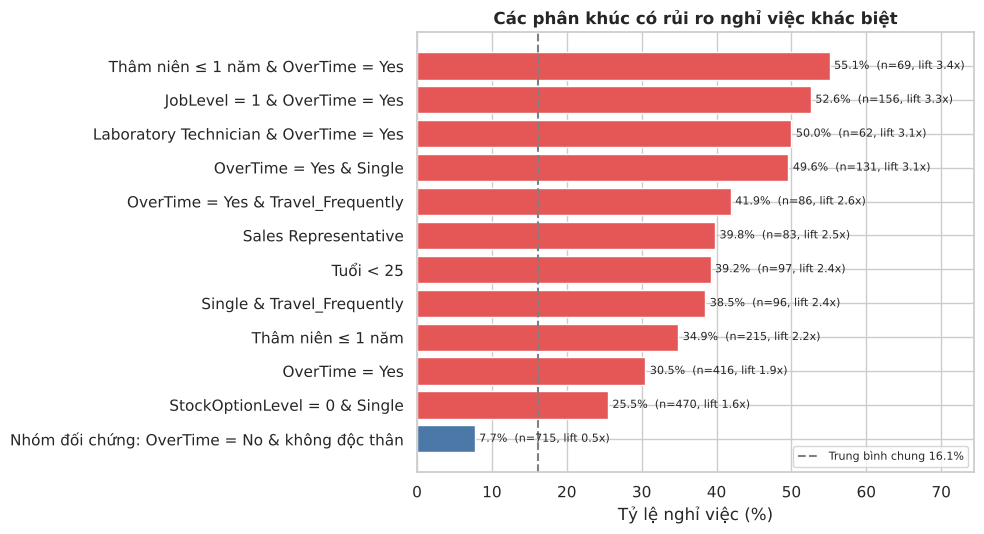

In [44]:
# 4.2 Biểu đồ các phân khúc rủi ro (lift so với tỷ lệ nghỉ việc chung)
s = seg_tbl.sort_values("ty_le_nghi_%")
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(s["phan_khuc"], s["ty_le_nghi_%"], color=[C_YES if v > overall else C_NO for v in s["ty_le_nghi_%"]])
for i, (r, n, lf) in enumerate(zip(s["ty_le_nghi_%"], s["n"], s["lift"])):
    ax.text(r + 0.6, i, f"{r:.1f}%  (n={n}, lift {lf:.1f}x)", va="center", fontsize=8)
ax.axvline(overall, ls="--", color="gray", label=f"Trung bình chung {overall:.1f}%")
ax.set_xlim(0, s["ty_le_nghi_%"].max() * 1.35); ax.legend(loc="lower right", fontsize=8)
ax.set_xlabel("Tỷ lệ nghỉ việc (%)"); ax.set_title("Các phân khúc có rủi ro nghỉ việc khác biệt")
plt.tight_layout(); save_fig("fig16_risk_segments.png"); plt.show()

## 4.3 Tóm tắt các phát hiện nổi bật nhất

Xếp theo mức độ ảnh hưởng (dựa trên effect size, tỷ lệ chênh lệch và độ vững sau hiệu chỉnh Bonferroni):

1. **Làm thêm giờ là yếu tố mạnh và rõ nhất.** Nhóm `OverTime = Yes` nghỉ việc **30,5%** so với **10,4%**; odds ratio ≈ **3,8** (KTC 95%: 2,8–5,0). Kiểm định CMH xác nhận hiệu ứng **không bị nhiễu** bởi hôn nhân hay cấp bậc (OR gộp ≈ 4,0 ở cả hai cách phân tầng). Nhân viên độc thân làm thêm giờ nghỉ tới **49,6%** do hai yếu tố cộng lại.
2. **Nhân viên trẻ và mới vào làm có nguy cơ cao nhất.** Nhóm 18–24 tuổi nghỉ **39,2%**, nhóm thâm niên ≤ 1 năm nghỉ **34,9%** (so với 12,9% của người trên 1 năm). Rủi ro giảm dần theo thâm niên.
3. **Thu nhập thấp có liên hệ với nghỉ việc nhưng phần lớn là hiệu ứng của cấp bậc.** Thu nhập trung vị nhóm nghỉ việc là 3.202 so với 5.204. Tuy nhiên `JobLevel` và `MonthlyIncome` tương quan 0,92; khi so sánh *trong cùng một cấp bậc*, chênh lệch thu nhập chỉ còn có ý nghĩa ở 2/5 cấp (JobLevel 1 và 4, mức 0,05 chưa hiệu chỉnh). Vì vậy "tăng lương đại trà" chưa phải kết luận được dữ liệu ủng hộ.
4. **Vị trí công việc phân hóa mạnh:** Sales Representative **39,8%**, Laboratory Technician **23,9%**, Human Resources **23,1%**, trong khi Research Director chỉ **2,5%** và Manager **4,9%**.
5. **Các yếu tố bổ trợ:** độc thân (25,5%), đi công tác thường xuyên (24,9%), không có quyền chọn cổ phiếu (24,4%; vẫn gấp 2,4 lần về odds trong nhóm đã kết hôn/ly hôn theo CMH), mức hài lòng/tham gia công việc thấp (ví dụ JobInvolvement mức 1 là 33,7%, WorkLifeBalance mức 1 là 31,2%).
6. **Giả thuyết không được ủng hộ:** thời gian từ lần thăng chức gần nhất (H4), giới tính (đối chứng), phòng ban (sau hiệu chỉnh Bonferroni). Khoảng cách đi làm có xu hướng tăng ở nhóm ≥ 11 km: không có ý nghĩa với Bonferroni (p ≈ 0,07) nhưng có ý nghĩa với FDR, nên chỉ là bằng chứng yếu.
7. **Mô hình hồi quy logistic** (đã loại `Department` do đa cộng tuyến) đạt ROC-AUC 0,79 trên tập test và **0,83** trung bình qua 10 lần lặp 5-fold CV (khoảng 0,78–0,89). Theo hệ số chuẩn hóa, `OverTime`, khối thâm niên/cấp bậc và số công ty đã làm là mạnh nhất, tiếp theo là đi công tác, mức hài lòng, vị trí công việc và độc thân. Các kết luận chính ở trên **vẫn đứng vững khi xét đa biến**. Dùng làm danh sách ưu tiên, **top 20%** điểm rủi ro bao phủ khoảng **60%** số người nghỉ.

## 4.4 Đề xuất giải pháp ứng dụng

| Phát hiện | Giải pháp đề xuất | Chỉ số theo dõi |
|---|---|---|
| Làm thêm giờ làm nguy cơ nghỉ việc tăng gấp khoảng 3 lần | Đặt trần giờ làm thêm theo tháng; rà soát phân bổ khối lượng công việc, ưu tiên các nhóm Lab Technician, Sales Representative; quy đổi giờ làm thêm thành nghỉ bù hoặc phụ cấp rõ ràng | Tỷ lệ nhân viên OverTime, tỷ lệ nghỉ việc nhóm OverTime |
| Nghỉ việc tập trung ở người trẻ và năm đầu | Chương trình onboarding 12 tháng: mentor, mốc đánh giá ở tháng 3/6/12, lộ trình phát triển rõ ràng cho nhân viên < 25 tuổi | Tỷ lệ giữ chân sau 12 tháng |
| Vị trí Sales Representative, Lab Technician, HR có rủi ro cao | Khảo sát sâu (phỏng vấn nghỉ việc và phỏng vấn giữ chân) cho các vị trí này; xem lại cơ chế thưởng, áp lực chỉ tiêu và lộ trình lên cấp | Tỷ lệ nghỉ việc theo vị trí |
| Thu nhập thấp gắn với cấp bậc thấp | Thay vì tăng lương đại trà, rà soát thang lương **theo cấp bậc** và lộ trình thăng cấp từ JobLevel 1 sang 2 (nhóm có tỷ lệ nghỉ việc 26,3%) | Tỷ lệ nghỉ việc tại JobLevel 1, thời gian lên JobLevel 2 |
| Nhóm không có quyền chọn cổ phiếu, độc thân, đi công tác nhiều | Thí điểm phúc lợi giữ chân (cổ phiếu/thưởng dài hạn) cho nhóm rủi ro; giảm tần suất công tác với nhân viên đã có tín hiệu rủi ro | Mức tham gia chương trình, tỷ lệ nghỉ việc nhóm thí điểm |
| Mức hài lòng và gắn kết thấp | Khảo sát định kỳ ngắn (pulse survey) về WorkLifeBalance, JobInvolvement; HR chủ động trao đổi với nhân viên điểm thấp | Điểm hài lòng trung bình, tỷ lệ nhân viên điểm 1 |
| Cần ưu tiên nguồn lực | Dùng điểm rủi ro để chọn **top 10–20%** nhân viên cho phỏng vấn giữ chân (top 20% bao phủ khoảng 60% số người nghỉ, precision khoảng 48%, mục 3.12c); kết hợp phân khúc ở mục 4.1: nhóm làm thêm giờ (28% nhân viên) chiếm khoảng 54% số người nghỉ, nhóm JobLevel 1 làm thêm giờ (11% nhân viên) chiếm khoảng 35% | Precision/recall của danh sách top-k, cập nhật hằng quý |

> **Lưu ý khi áp dụng:** các mối liên hệ là *tương quan*, chưa chứng minh nhân quả. Nên thí điểm có nhóm đối chứng (A/B) trước khi triển khai toàn công ty.

## 4.5 Giới hạn của tập dữ liệu

- **Dữ liệu mô phỏng:** tập dữ liệu do IBM tạo ra với mục đích minh họa, không phải dữ liệu thực của doanh nghiệp, nên kết luận không nên khái quát hóa trực tiếp ra thực tế.
- **Lát cắt thời điểm:** không có chiều thời gian (không biết ngày nghỉ việc, không theo dõi thay đổi lương/hài lòng theo thời gian) nên không thể kết luận quan hệ nhân quả hay phân tích sống sót (survival).
- **Không có lý do nghỉ việc thực sự:** không phân biệt tự nguyện/bị cho thôi việc/nghỉ hưu.
- **Mất cân bằng lớp và cỡ mẫu nhỏ:** chỉ có 237 trường hợp nghỉ việc; nhiều nhóm con có n nhỏ (ví dụ Divorced + StockOptionLevel 0 chỉ có 8 người; Sales Representative 83 người) nên ước lượng kém ổn định.
- **Đặc điểm cấu trúc bất thường:** `PerformanceRating` chỉ có 2 giá trị; không có nhân viên độc thân nào có `StockOptionLevel` ≥ 1 nên hiệu ứng cổ phiếu và hôn nhân bị trộn lẫn.
- **Đa cộng tuyến:** các cặp biến tương quan cao (JobLevel–MonthlyIncome 0,92; YearsInCurrentRole–YearsAtCompany 0,85) khiến hệ số hồi quy từng biến kém ổn định và không nên diễn giải riêng lẻ.
- **Nhiều kiểm định:** Bonferroni khá bảo thủ; phân tích độ nhạy với FDR cho thấy 4 biến (`DistanceFromHome`, `Department`, `EducationField`, `DailyRate`) đổi kết luận, nên các kết luận này chỉ là bằng chứng yếu.
- **Mô hình tham chiếu:** AUC dao động khoảng 0,78–0,89 giữa các lần chia dữ liệu; precision ở ngưỡng 0,5 khoảng 0,40 và ở top 20% khoảng 0,48, nên điểm rủi ro chỉ dùng để **ưu tiên trao đổi**, không để ra quyết định nhân sự ở mức cá nhân. Mô hình chưa được kiểm định trên dữ liệu ngoài (dữ liệu mới, công ty khác).

## 4.6 Hướng mở rộng

1. Thu thập dữ liệu theo thời gian (ngày vào, ngày nghỉ, lịch sử lương, điểm hài lòng định kỳ) để dùng **phân tích sống sót** (Kaplan–Meier, Cox).
2. Thử các mô hình phi tuyến (Random Forest, Gradient Boosting) kết hợp **SHAP** để giải thích; xử lý mất cân bằng bằng trọng số lớp, SMOTE hoặc tinh chỉnh ngưỡng quyết định; đánh giá bằng PR-AUC và recall tại top-k.
3. Bổ sung dữ liệu về lý do nghỉ việc, đánh giá của quản lý, thị trường lao động để tách các nguyên nhân khác nhau.
4. Xây dựng phân tích **chi phí – lợi ích**: chi phí thay thế nhân viên so với chi phí chương trình giữ chân để ưu tiên can thiệp.
5. Thiết kế thử nghiệm A/B cho các giải pháp đề xuất (ví dụ trần giờ làm thêm, chương trình mentor).

In [45]:
# 4.7 Lưu kết quả: số liệu tổng hợp (JSON) và dữ liệu đã làm sạch/mã hóa (CSV) để tái sử dụng
def _to_py(o):
    # Chuyển kiểu numpy/pandas sang kiểu Python để ghi JSON
    if hasattr(o, "item"):
        return o.item()
    return str(o)

with open(os.path.join(OUT_DIR, "results.json"), "w", encoding="utf-8") as f:
    json.dump(R, f, ensure_ascii=False, indent=2, default=_to_py)
df_model.to_csv(os.path.join(OUT_DIR, "hr_attrition_model_ready.csv"), index=False)
print("Đã lưu:", sorted(os.listdir(OUT_DIR)))
print("Các hình:", sorted(os.listdir(FIG_DIR)))

Đã lưu: ['hr_attrition_model_ready.csv', 'hypothesis_summary.csv', 'logreg_coefficients.csv', 'outlier_table.csv', 'results.json', 'risk_segments.csv', 'screening_tests.csv', 'topk_risk.csv']
Các hình: ['fig01_attrition_distribution.png', 'fig02_boxplot_outliers.png', 'fig03_skew_transform.png', 'fig04_effect_ranking.png', 'fig05_overtime.png', 'fig06_income.png', 'fig06b_income_by_joblevel.png', 'fig07_scatter_income.png', 'fig08_age_tenure.png', 'fig09_promotion.png', 'fig10_satisfaction.png', 'fig11_stock_option.png', 'fig12_travel_marital_distance.png', 'fig13_jobrole_department.png', 'fig14_correlation_heatmap.png', 'fig15_logreg.png', 'fig16_risk_segments.png']


## 4.8 Dựng báo cáo PDF từ kết quả notebook

Toàn bộ hình trong `figures/` và bảng trong `outputs/` vừa sinh ra là đầu vào của báo cáo `Bao_cao_HR_Attrition.pdf`. Sau khi chạy xong notebook, chạy lệnh `python generate_report.py` (thông tin nhóm và logo khai báo trong `report_config.py`) để dựng lại báo cáo, nhờ đó mọi số liệu trong báo cáo luôn khớp với notebook.
